# Crop-margin diagnostic: does blank space around the writing hurt the reader?

**Run top to bottom on your Mac. No training and no new inference:** this notebook only reads the saved results in `Assignment/claude_margin_diagnostic_20261109/` (Claude, 9 Nov 2026).

**The question.** The reader resizes every line crop to **64 px high** before reading it. If a crop has a lot of empty board above and below the writing, the writing itself ends up only a few pixels tall. Does that cause errors, especially **missing characters (deletions)**, on the JH/DS unfamiliar-writer crops?

**What was done**
1. For each of the 160 JH/DS crops, a rectangle around the writing was chosen **from the image only** (ink-detection rule plus padding, every changed box checked by eye so no stroke is cut, 4 set by hand).
2. The groups and the pass/fail rule were **frozen in `PROTOCOL.json` before any new reading**.
3. The **same frozen S1 seed-1 reader** read each crop twice: the original file and the tightened crop.
4. CER and deletion/substitution/insertion counts were compared, by group.

Original images, labels and earlier results were not changed.

In [1]:
from pathlib import Path
import json, hashlib, html
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display, HTML, Markdown
ASSIGNMENT_OVERRIDE = None          # set to your Assignment folder if the search below fails
cands = [Path(ASSIGNMENT_OVERRIDE)] if ASSIGNMENT_OVERRIDE else []
for base in [Path.cwd(), *Path.cwd().parents]:
    cands += [base, base / 'Assignment']
A = next(p.resolve() for p in cands if (p / 'claude_margin_diagnostic_20261109/RESULTS.json').is_file())
D = A / 'claude_margin_diagnostic_20261109'
P = json.loads((D / 'PROTOCOL.json').read_text())
boxes = {r['name']: r for r in json.loads((D / 'boxes_final.json').read_text())}
R = json.loads((D / 'RESULTS.json').read_text())
df = pd.DataFrame([{**{k: v for k, v in x.items() if k not in ('o', 't')},
                    **{f'orig_{k}': v for k, v in x['o'].items()}, **{f'tight_{k}': v for k, v in x['t'].items()}}
                   for x in R['crops']])
# the source images are untouched: their hashes still match the ones recorded before inference
bad = [n for n, r in boxes.items() if hashlib.sha256((A / r['src']).read_bytes()).hexdigest() != r['sha256']]
assert not bad, bad
assert hashlib.sha256((D / 'boxes_final.json').read_bytes()).hexdigest() == P['boxes_sha256'], 'boxes changed after the protocol was frozen'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Assignment folder:', A)
print(f"{len(df)} crops; source hashes unchanged; boxes identical to the frozen protocol ({P['created']})")
display(Markdown('**Pass/fail rule, written before any new reading:** ' + P['supported_if']))

Assignment folder: /sessions/rcw-01vkkhtsx22qwuxufc3jfk4j/mnt/Computer Vision & Deep Learning/Assignment
160 crops; source hashes unchanged; boxes identical to the frozen protocol (2026-11-08 17:21:31 UTC)


**Pass/fail rule, written before any new reading:** ALL of: (1) large-margin group: mean CER change (tight - original) has photo-cluster bootstrap 95% CI below 0; (2) large-margin deletions decrease; (3) large-margin change minus control change has 95% CI below 0. Otherwise: not supported.

## 1. Why margins can matter: what the reader actually sees

Each crop is scaled so that its **height becomes 64 px** (its width follows, then it is padded to at least 1024 px wide). Below, the left image is the *original crop as the reader sees it* (64 px high) and the right image is the *tightened crop as the reader sees it*. Same pixels of writing, different scale.

Example: a 300 px-high crop whose writing is 60 px tall becomes 64 px high, so the writing shrinks to about **13 px**. Cropped to about 90 px around the writing, the same writing becomes about **43 px** tall.

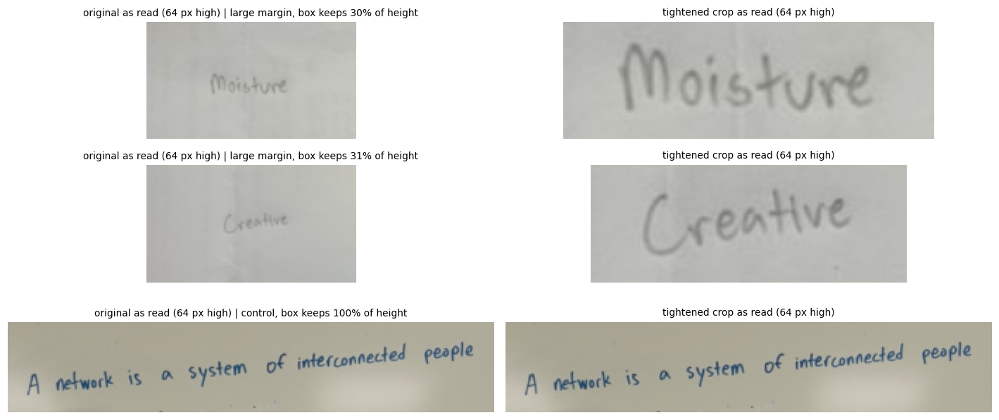

In [2]:
def reader_view(im, H=64):
    return im.resize((max(1, round(im.width * H / im.height)), H), Image.BILINEAR)

def load(name):
    r = boxes[name]
    return ImageOps.exif_transpose(Image.open(A / r['src'])).convert('RGB'), Image.open(D / r['tight_file']).convert('RGB')

examples = df[df.group.eq('large margin')].sort_values('kept_h').name.tolist()[:2] + \
           df[df.group.eq('control')].sort_values('kept_h', ascending=False).name.tolist()[:1]
fig, axes = plt.subplots(len(examples), 2, figsize=(13, 1.9 * len(examples)))
for (a, b), n in zip(axes, examples):
    o, t = load(n); x = df.set_index('name').loc[n]
    a.imshow(reader_view(o)); a.set_title(f'original as read (64 px high) | {x.group}, box keeps {x.kept_h:.0%} of height', fontsize=9)
    b.imshow(reader_view(t)); b.set_title('tightened crop as read (64 px high)', fontsize=9)
    a.axis('off'); b.axis('off')
fig.tight_layout(); plt.show()

## 2. The rectangles and the groups

The **dose** of the change is how much of the crop's height the rectangle keeps:
- **Large margin:** the box keeps **60% of the height or less**, so the writing becomes at least 1.7× larger.
- **Control:** the box keeps **85% or more**, so little changes. These include crops the reader already read well.
- **Middle:** in between.
- **Flagged:** 4 crops with known label or crop questions from the earlier audits, reported separately.

Green rectangles below are the saved coordinates (`boxes_final.json`).

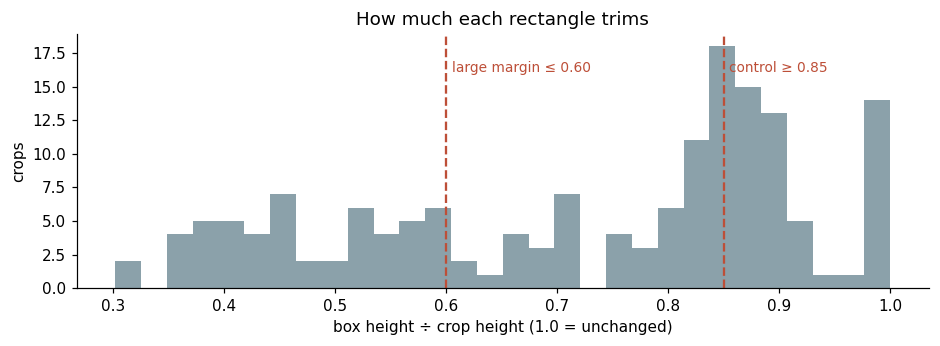

,crops
group,
middle,57
large margin,51
control,48
flagged,4


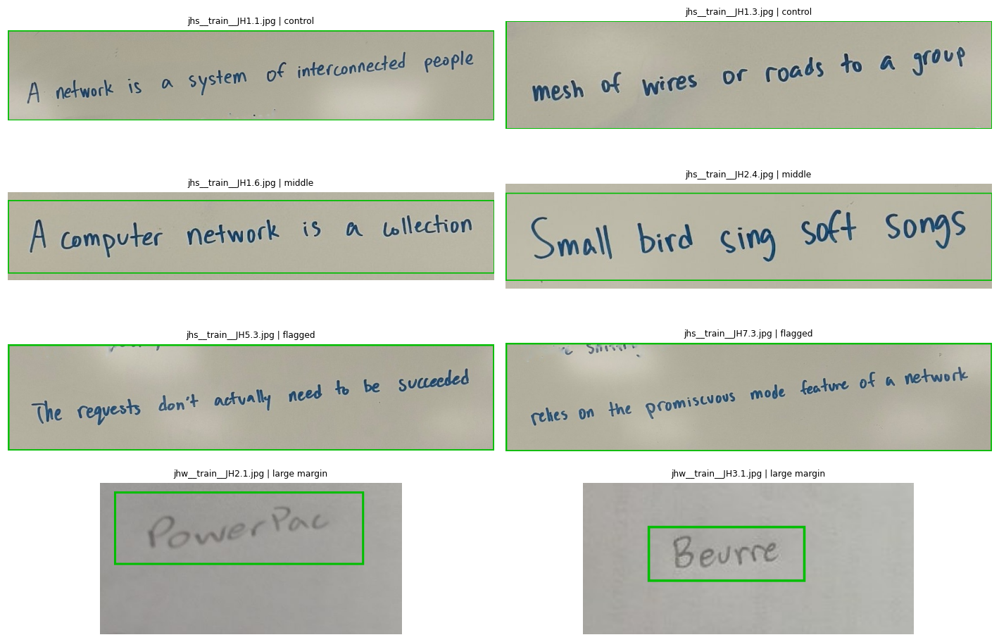

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(df.kept_h, bins=30, color='#8ba1aa')
for v, lab in [(0.6, 'large margin ≤ 0.60'), (0.85, 'control ≥ 0.85')]:
    ax.axvline(v, color='#bd4f38', linestyle='--'); ax.text(v + 0.005, ax.get_ylim()[1] * 0.85, lab, fontsize=9, color='#bd4f38')
ax.set(xlabel='box height ÷ crop height (1.0 = unchanged)', ylabel='crops', title='How much each rectangle trims')
plt.show()
display(df.group.value_counts().rename('crops').to_frame())

def overlay(name):
    o, _ = load(name); r = boxes[name]; im = o.copy()
    ImageDraw.Draw(im).rectangle(r['box'], outline=(0, 190, 0), width=max(2, im.height // 60)); return im
sample = df.groupby('group').head(2).name.tolist()
fig, axes = plt.subplots(len(sample) // 2 + len(sample) % 2, 2, figsize=(13, 1.7 * (len(sample) // 2 + 1)))
for ax, n in zip(axes.flat, sample):
    ax.imshow(overlay(n)); ax.set_title(f"{n} | {df.set_index('name').loc[n, 'group']}", fontsize=8); ax.axis('off')
for ax in list(axes.flat)[len(sample):]: ax.axis('off')
fig.tight_layout(); plt.show()

## 3. Results

CER = character edits ÷ label length (lower is better), averaged per crop. **Deletions** are characters in the label that the reader left out, **substitutions** are wrong characters, and **insertions** are extra characters (from one optimal alignment). The 95% interval resamples whole source photos.

,crops,CER original %,CER tight %,change (pp),95% interval (pp),deletions,substitutions,insertions,better / worse
group,,,,,,,,,
large margin,51,35.4,6.3,-29.1,-36.2 .. -19.7,323 -> 24,327 -> 51,41 -> 6,40 / 2
middle,57,12.5,5.7,-6.8,-11.1 .. -3.1,130 -> 34,135 -> 69,17 -> 14,30 / 5
control,48,24.6,19.5,-5.1,-7.3 .. -2.8,223 -> 187,249 -> 191,28 -> 23,29 / 3
flagged,4,43.4,37.5,-5.9,-17.6 .. +0.0,21 -> 15,47 -> 48,2 -> 3,1 / 0
all 156 (excl. flagged),156,23.7,10.1,-13.6,-18.9 .. -8.3,676 -> 245,711 -> 311,86 -> 43,99 / 10


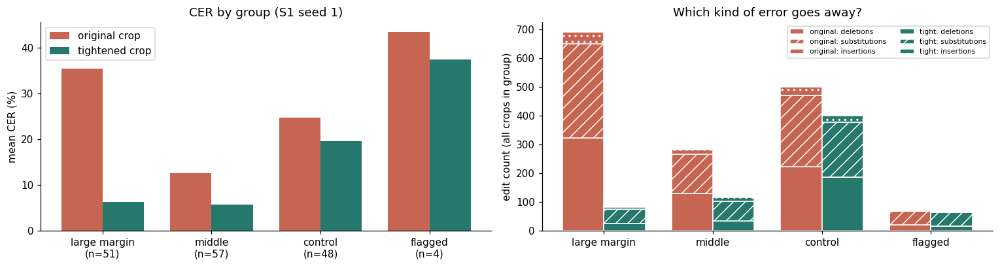

In [4]:
g = R['groups']
tab = pd.DataFrame([{'group': k, 'crops': v['n'], 'CER original %': 100 * v['cer_original'], 'CER tight %': 100 * v['cer_tight'],
                     'change (pp)': 100 * v['change'],
                     '95% interval (pp)': f"{100*v['ci'][0]:+.1f} .. {100*v['ci'][1]:+.1f}" if v['ci'] else '',
                     'deletions': f"{v['D'][0]} -> {v['D'][1]}", 'substitutions': f"{v['S'][0]} -> {v['S'][1]}",
                     'insertions': f"{v['I'][0]} -> {v['I'][1]}", 'better / worse': f"{v['better']} / {v['worse']}"} for k, v in g.items()]).set_index('group')
display(tab.round(1))

order = ['large margin', 'middle', 'control', 'flagged']
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(order)); w = .38
axes[0].bar(x - w/2, [100 * g[k]['cer_original'] for k in order], w, color='#c56552', label='original crop')
axes[0].bar(x + w/2, [100 * g[k]['cer_tight'] for k in order], w, color='#26786c', label='tightened crop')
axes[0].set(xticks=x, xticklabels=[f"{k}\n(n={g[k]['n']})" for k in order], ylabel='mean CER (%)', title='CER by group (S1 seed 1)')
axes[0].legend()
for i, k in enumerate(order):
    for j, (arm, col) in enumerate([(0, '#c56552'), (1, '#26786c')]):
        vals = [g[k]['D'][arm], g[k]['S'][arm], g[k]['I'][arm]]
        bottom = 0
        for v, hatch, lab in zip(vals, ['', '//', '..'], ['deletions', 'substitutions', 'insertions']):
            axes[1].bar(i + (j - .5) * w, v, w, bottom=bottom, color=col, hatch=hatch, edgecolor='white',
                        label=f"{'original' if arm == 0 else 'tight'}: {lab}" if i == 0 else None)
            bottom += v
axes[1].set(xticks=x, xticklabels=order, ylabel='edit count (all crops in group)', title='Which kind of error goes away?')
axes[1].legend(fontsize=7, ncol=2); fig.tight_layout(); plt.show()

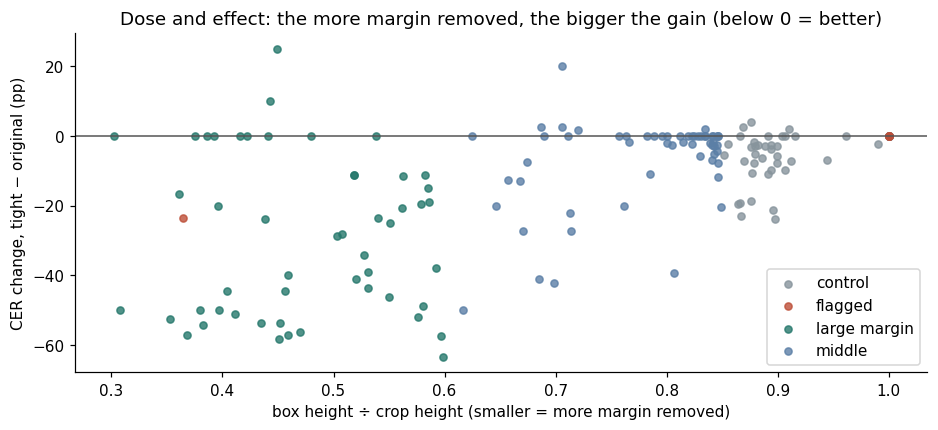

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
cols = {'large margin': '#26786c', 'middle': '#5b7fa6', 'control': '#87949c', 'flagged': '#bd4f38'}
for k, sub in df.groupby('group'):
    ax.scatter(sub.kept_h, 100 * sub.d, s=22, alpha=.8, color=cols[k], label=k)
ax.axhline(0, color='#555', linewidth=1)
ax.set(xlabel='box height ÷ crop height (smaller = more margin removed)', ylabel='CER change, tight − original (pp)',
       title='Dose and effect: the more margin removed, the bigger the gain (below 0 = better)')
ax.legend(); plt.show()

## 4. The pre-declared decision

In [6]:
c = R['criteria']; did = R['diff_in_diff']
display(pd.DataFrame([
    {'criterion': '1. large-margin CER change: 95% interval below 0', 'value': f"{100*g['large margin']['change']:+.1f} pp ({100*g['large margin']['ci'][0]:+.1f} .. {100*g['large margin']['ci'][1]:+.1f})", 'met': c['ci_below_0']},
    {'criterion': '2. large-margin deletions decrease', 'value': f"{g['large margin']['D'][0]} -> {g['large margin']['D'][1]}", 'met': c['deletions_down']},
    {'criterion': '3. large-margin change minus control change: interval below 0', 'value': f"{100*did[0]:+.1f} pp ({100*did[1]:+.1f} .. {100*did[2]:+.1f})", 'met': c['did_ci_below_0']},
]).set_index('criterion'))
display(Markdown(f"**Verdict: {R['verdict']}.** Scorer check: the original-crop readings on the Mac match the saved RunPod GPU readings "
                 f"on {R['reproducibility']['identical_to_saved_gpu_S1']}/160 crops exactly, with the same mean CER."))

,value,met
criterion,,
1. large-margin CER change: 95% interval below 0,-29.1 pp (-36.2 .. -19.7),True
2. large-margin deletions decrease,323 -> 24,True
3. large-margin change minus control change: interval below 0,-24.0 pp (-31.7 .. -13.2),True


**Verdict: supported.** Scorer check: the original-crop readings on the Mac match the saved RunPod GPU readings on 114/160 crops exactly, with the same mean CER.

## 5. Look at the crops: regressions first, then improvements and controls

Each panel: the original crop with the green rectangle, then the tightened crop. Under it: the label and both readings, coloured against the label (green = correct, red = wrong or extra, struck-through red = missing). The saved side-by-side images are also in `claude_margin_diagnostic_20261109/side_by_side/`.

### All 10 regressions (tightened reading worse)

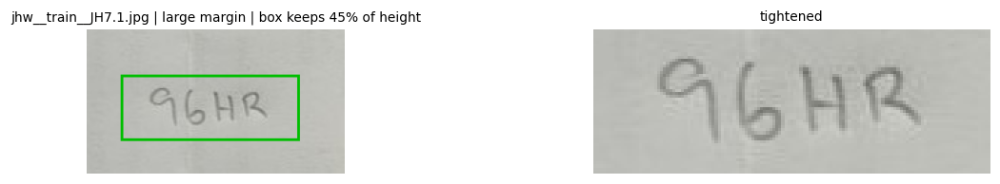

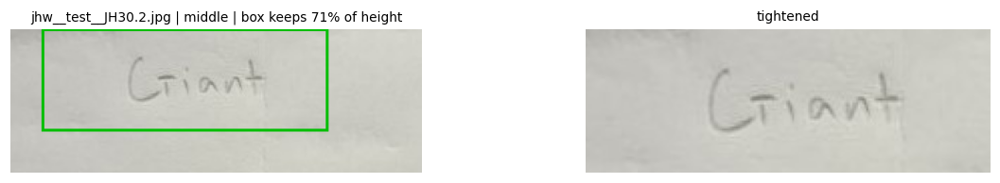

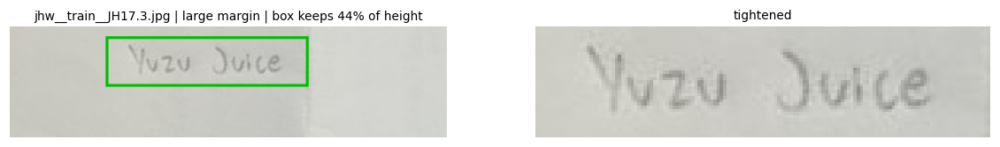

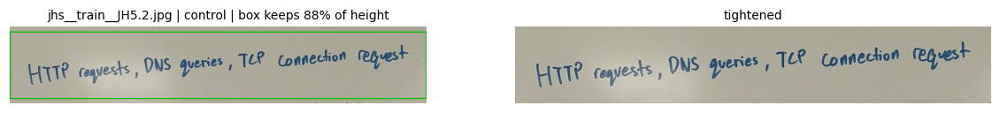

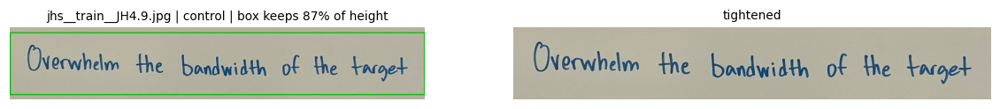

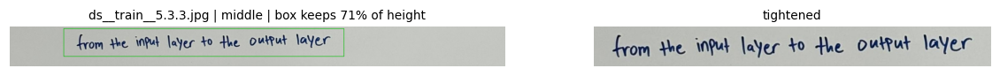

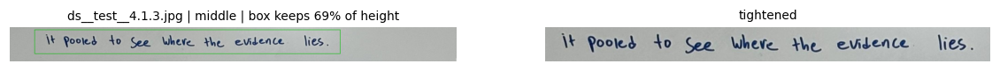

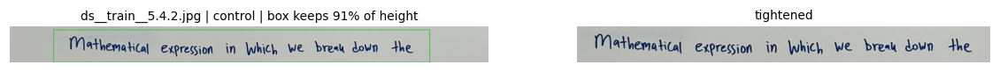

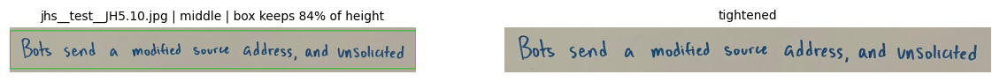

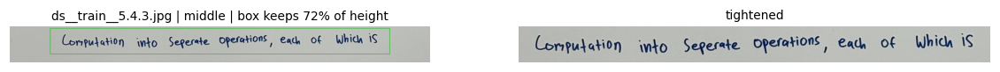

In [7]:
def norm(s): return ' '.join(str(s).lower().split())
def coloured(label, pred):
    a, b = norm(label), norm(pred); n, m = len(a), len(b)
    Dm = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): Dm[i][0] = i
    for j in range(m + 1): Dm[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            Dm[i][j] = min(Dm[i-1][j] + 1, Dm[i][j-1] + 1, Dm[i-1][j-1] + (a[i-1] != b[j-1]))
    out = []; i, j = n, m
    while i or j:
        if i and j and Dm[i][j] == Dm[i-1][j-1] + (a[i-1] != b[j-1]):
            out.append(f'<span style="color:{"#206b3c" if a[i-1]==b[j-1] else "#b42318"}">{html.escape(b[j-1])}</span>'); i -= 1; j -= 1
        elif j and Dm[i][j] == Dm[i][j-1] + 1:
            out.append(f'<span style="color:#b42318;background:#fff0ed">{html.escape(b[j-1])}</span>'); j -= 1
        else:
            out.append(f'<del style="color:#b42318">{html.escape(a[i-1])}</del>'); i -= 1
    return ''.join(reversed(out)) or '<em>empty</em>'

def show(name):
    x = df.set_index('name').loc[name]; o, t = load(name)
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 1.8), gridspec_kw=dict(width_ratios=[o.width / o.height, t.width / t.height]))
    a.imshow(overlay(name)); b.imshow(t); a.axis('off'); b.axis('off')
    a.set_title(f'{name} | {x.group} | box keeps {x.kept_h:.0%} of height', fontsize=9); b.set_title('tightened', fontsize=9)
    plt.show()
    display(HTML(f'<p style="margin:0"><b>label:</b> {html.escape(x.label)}</p>'
                 f'<p style="margin:0;font:14px monospace">original CER {x.orig_cer:.0%}: {coloured(x.label, x.pred_original)}</p>'
                 f'<p style="margin:0 0 14px;font:14px monospace">tightened CER {x.tight_cer:.0%}: {coloured(x.label, x.pred_tight)}</p>'))

worse = df[df.d > 1e-12].sort_values('d', ascending=False)
display(Markdown(f'### All {len(worse)} regressions (tightened reading worse)'))
for n in worse.name: show(n)

### The 8 biggest improvements (of 100)

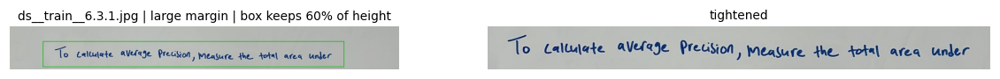

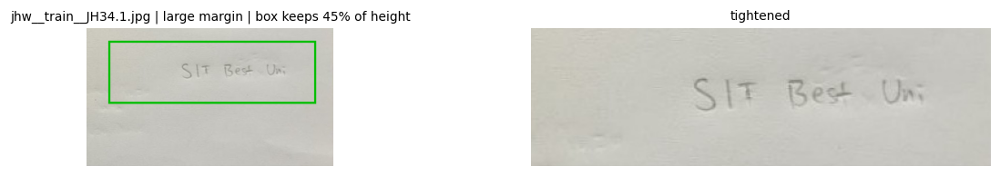

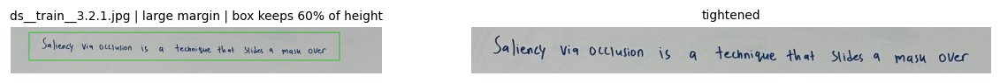

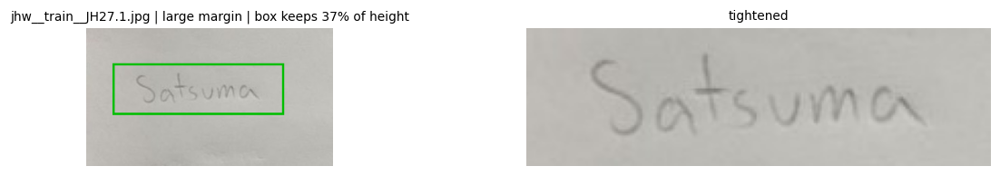

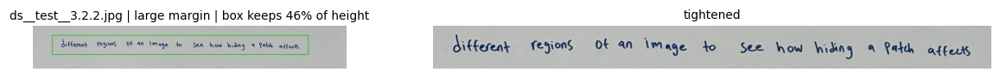

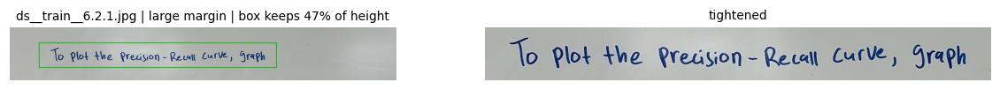

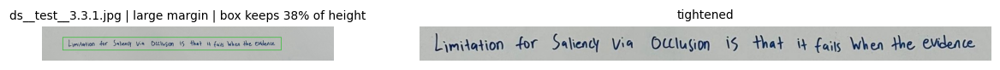

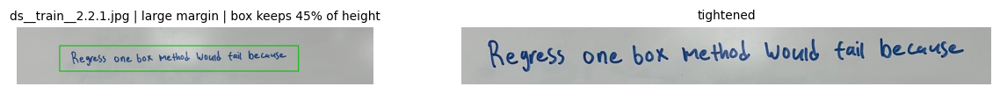

In [8]:
better = df[df.d < -1e-12].sort_values('d')
display(Markdown(f'### The 8 biggest improvements (of {len(better)})'))
for n in better.name[:8]: show(n)

### Controls: tight crops where little was trimmed (3 read perfectly before, 3 with errors before)

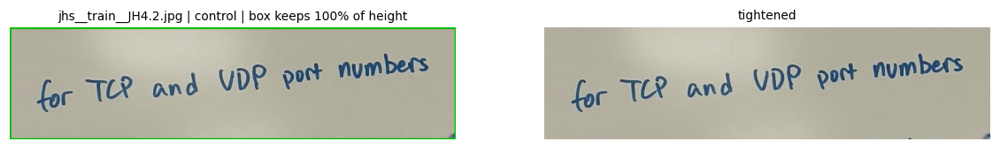

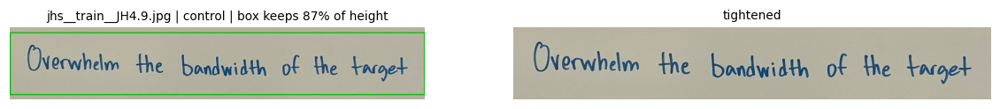

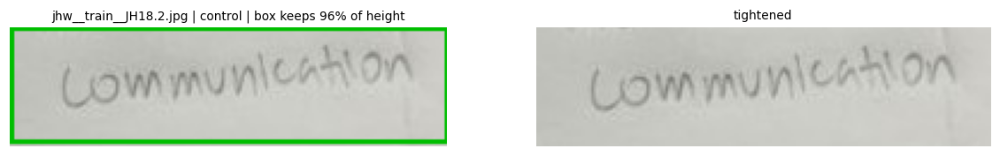

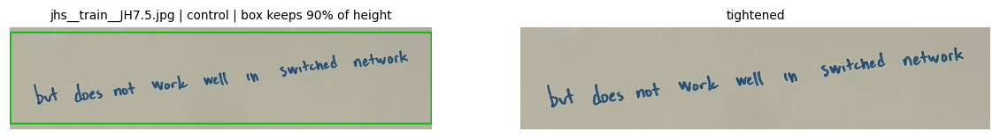

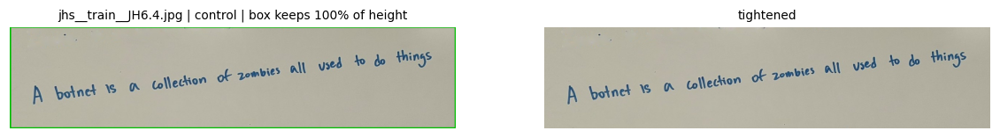

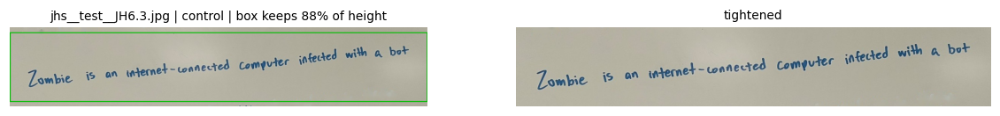

In [9]:
ctrl = df[df.group.eq('control')]
display(Markdown('### Controls: tight crops where little was trimmed (3 read perfectly before, 3 with errors before)'))
for n in list(ctrl[ctrl.orig_cer.eq(0)].name[:3]) + list(ctrl[ctrl.orig_cer > 0].sort_values('orig_cer', ascending=False).name[:3]): show(n)

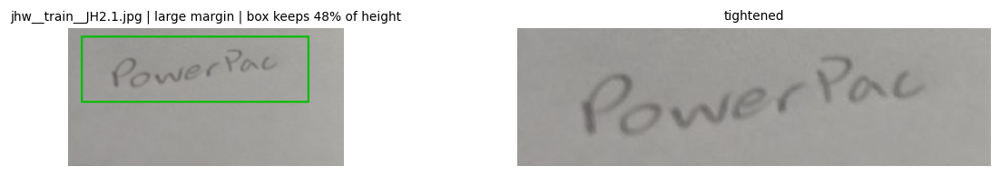

In [10]:
# Look at any crop yourself: change the name (see df.name for all 160) or the group
show(df[df.group.eq('large margin')].name.iloc[0])

## 6. What this shows, and what it does not

**Shows**
- On crops with large margins, tightening the crop cut S1's error from about **35% to about 6%**, and deletions almost disappeared (**323 → 24**). The pre-declared rule is met.
- The JH/DS "unfamiliar-writer" error (about 24% on the original crops) is **largely a crop-scale effect** of how those crops were cut. With tight crops it is about **10%**. That is still above familiar-writer sentences (about 2.4%) and Jy (about 5.5%, whose crops were already tight), so a smaller real gap remains.
- Even controls improved a little (about −5 points), so removing side margins, stray marks and faint ghost writing also helps.

**Does not show**
- That the app has this problem. The app's crops come from the text detector, whose margins have not been measured yet.
- That an automatic tightening step works. These boxes are an oracle: a rule plus visual checks and 4 manual exceptions. The same rule missed light strokes on Jy.
- Anything about S0 or G0. Only S1 seed 1 was read. G0's earlier new-writer advantage may partly reflect robustness to small text; that is untested.

**Next (not started; no training yet)**
1. Read the same tight crops with S0 and G0 seed 1 (a few minutes, no training).
2. Measure the margins of the detector's crops in the full-photo path; only if they are loose, test an automatic tightening step on full photos.
3. If wanted later: scale/margin augmentation in training, with matched seeds.

JH/DS has now informed several decisions, so any final claim about new writers needs fresh writers.

## 7. Added 9 Nov: S0, S1 and G0 (both seeds) on the same frozen crops

Sections 1–6 above are unchanged: they are the S1 seed-1 result. This section reads the **same 160 crops and the same rectangles** with all six trained readers: **S0, S0s2, S1, S1s2, G0, G0s2**. It uses the same Mac scorer and settings, and labels and boxes are unchanged. The results come from `RESULTS_MODELS.json`, produced by `analyse_models.py`.

Questions:
1. Does tightening help every model, and does it remove deletions for every model?
2. **Does G0 still beat S0 once the text is a sensible size?** Earlier, G0's advantage on these writers was measured on the loose original crops.
3. Are the answers the same for all 160 crops and for the 156 without the 4 flagged crops?
4. What errors remain after tightening, and what got worse?

"S0avg" etc. are per-crop means of the two seeds: a summary statistic, not a deployable model.

In [11]:
RM = json.loads((D / 'RESULTS_MODELS.json').read_text())
idt = RM['identity']
assert idt['boxes_sha256'] == P['boxes_sha256']
display(Markdown('**Models used (exported RunPod models, read on this Mac):**'))
display(pd.DataFrame([{'model': m, 'folder': v['model_dir'], 'inference.pdiparams sha256': v['inference_pdiparams_sha256'][:16] + '…',
                       'checkpoint sha256': v['checkpoint_sha256'][:16] + '…', 'export height': v['export_h'],
                       'RunPod export check': v['runpod_export_check'],
                       'original-crop readings identical to saved RunPod GPU readings': f"{v['gpu_readings_identical']}/160",
                       'mean CER here vs saved GPU (%)': f"{100*RM['models']['all 160'][m]['cer_original']:.2f} vs {100*v['gpu_mean_cer']:.2f}"}
                      for m, v in idt['models'].items()]).set_index('model'))
display(Markdown(f"**Scorer:** `{idt['scorer']}` (sha256 {idt['scorer_sha256'][:16]}…), {idt['runtime']}  \n"
                 f"**Input:** {idt['input']}  \n**Labels:** {idt['labels']}. "
                 "The Mac CPU readings are close to the GPU ones but not identical (about 1 point of mean CER at most), "
                 "so every comparison below uses only this scorer, for both arms and all models."))

**Models used (exported RunPod models, read on this Mac):**

,folder,inference.pdiparams sha256,checkpoint sha256,export height,RunPod export check,original-crop readings identical to saved RunPod GPU readings,mean CER here vs saved GPU (%)
model,,,,,,,
S0,results_strategies_s0s3/results/models/PP-OCRv...,299875f40b907b75…,db23d784a9bff2b3…,64,"30 crops, identical 100%",113/160,26.46 vs 27.39
S0s2,results_strategies_s0s3/results/models/PP-OCRv...,37dacba3beeb2ea3…,e98c874675789453…,64,"30 crops, identical 100%",121/160,26.10 vs 26.19
S1,results_strategies_s0s3/results/models/PP-OCRv...,067b34a571b6f152…,07e786e191c7a280…,64,"30 crops, identical 100%",114/160,24.21 vs 24.13
S1s2,results_strategies_s0s3/results/models/PP-OCRv...,fa33a85a8030e0d6…,d613a99befcde2f3…,64,"30 crops, identical 100%",99/160,25.84 vs 25.73
G0,results_guide_g0/results/models/PP-OCRv5_serve...,9c6d5a62fdc746ba…,5ea30e0146c982e5…,64,"30 crops, identical 100%",110/160,25.37 vs 24.77
G0s2,results_guide_g0/results/models/PP-OCRv5_serve...,ee5b94789b05cb38…,de24c7960f4cc650…,64,"30 crops, identical 100%",121/160,20.66 vs 20.78


**Scorer:** `score_static_mac.py` (sha256 f87dc2f56e5ce9ae…), {'paddle': '3.2.0', 'opencv': '5.0.0', 'python': '3.10.12', 'machine': 'aarch64', 'device': 'CPU', 'ir_optim': False, 'custom_passes': 'none'}  
**Input:** {'height': 64, 'min_width': 1024, 'resize': 'resize_norm_img_chinese (verbatim from PaddleOCR 91279fee): height 64, width follows the aspect ratio, padded to >= 1024; normalise to [-1, 1]', 'original_arm': 'untouched source files', 'tight_arm': 'lossless PNG crops (boxes_final.json)', 'decoder': 'cv2.imread (BGR)'}  
**Labels:** boxes_final.json labels = cases.json labels (unchanged). The Mac CPU readings are close to the GPU ones but not identical (about 1 point of mean CER at most), so every comparison below uses only this scorer, for both arms and all models.

### 7.1 Original vs tightened, per model

**all 160 crops**

,CER original %,CER tight %,change (pp),95% interval,deletions,substitutions,insertions,better / worse
model,,,,,,,,
S0,26.46,11.94,-14.52,-20.4 .. -8.8,755 -> 257,781 -> 376,80 -> 53,104 / 13
S0s2,26.10,11.61,-14.48,-20.0 .. -9.2,848 -> 272,689 -> 377,67 -> 39,109 / 9
S1,24.21,10.82,-13.39,-18.7 .. -8.1,697 -> 260,758 -> 359,88 -> 46,100 / 10
S1s2,25.84,11.09,-14.75,-20.7 .. -9.1,844 -> 274,703 -> 369,71 -> 43,104 / 11
G0,25.37,11.02,-14.35,-20.4 .. -8.7,990 -> 339,505 -> 270,46 -> 47,96 / 12
G0s2,20.66,9.23,-11.42,-16.7 .. -6.4,803 -> 285,517 -> 264,46 -> 33,96 / 14
S0avg,26.28,11.78,-14.50,-20.2 .. -9.2,802 -> 264,735 -> 376,74 -> 46,122 / 13
S1avg,25.03,10.96,-14.07,-19.6 .. -8.7,770 -> 267,730 -> 364,80 -> 44,113 / 12
G0avg,23.01,10.13,-12.89,-18.4 .. -7.6,896 -> 312,511 -> 267,46 -> 40,104 / 14


**156 excl. flagged crops**

,CER original %,CER tight %,change (pp),95% interval,deletions,substitutions,insertions,better / worse
model,,,,,,,,
S0,26.10,11.43,-14.67,-20.4 .. -9.0,724 -> 233,753 -> 348,77 -> 49,103 / 13
S0s2,25.70,11.11,-14.59,-20.0 .. -9.4,815 -> 244,657 -> 348,67 -> 38,108 / 9
S1,23.72,10.14,-13.58,-18.9 .. -8.3,676 -> 245,711 -> 311,86 -> 43,99 / 10
S1s2,25.36,10.50,-14.86,-20.6 .. -9.3,811 -> 249,667 -> 333,71 -> 42,103 / 11
G0,24.82,10.37,-14.45,-20.3 .. -8.9,934 -> 290,489 -> 255,46 -> 46,95 / 12
G0s2,20.20,8.75,-11.45,-16.5 .. -6.5,767 -> 257,495 -> 242,45 -> 31,95 / 14
S0avg,25.90,11.27,-14.63,-20.1 .. -9.3,770 -> 238,705 -> 348,72 -> 44,121 / 13
S1avg,24.54,10.32,-14.22,-19.6 .. -8.9,744 -> 247,689 -> 322,78 -> 42,112 / 12
G0avg,22.51,9.56,-12.95,-18.4 .. -7.9,850 -> 274,492 -> 248,46 -> 38,103 / 14


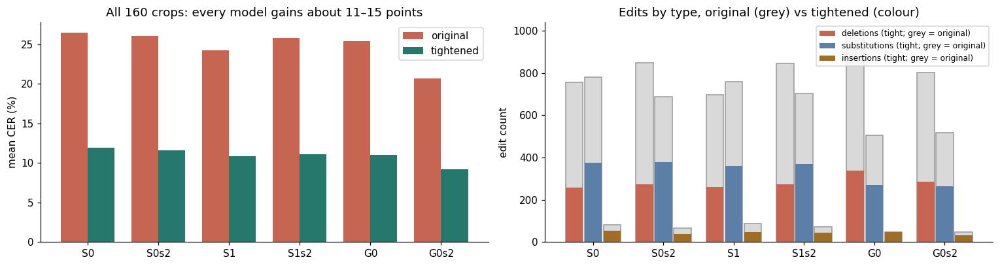

In [12]:
MODELS = ['S0', 'S0s2', 'S1', 'S1s2', 'G0', 'G0s2']; AVG = ['S0avg', 'S1avg', 'G0avg']
def model_table(scope):
    t = RM['models'][scope]
    return pd.DataFrame([{'model': m, 'CER original %': 100*t[m]['cer_original'], 'CER tight %': 100*t[m]['cer_tight'],
                          'change (pp)': 100*t[m]['change'], '95% interval': f"{100*t[m]['ci'][0]:+.1f} .. {100*t[m]['ci'][1]:+.1f}",
                          'deletions': f"{t[m]['D'][0]:.0f} -> {t[m]['D'][1]:.0f}", 'substitutions': f"{t[m]['S'][0]:.0f} -> {t[m]['S'][1]:.0f}",
                          'insertions': f"{t[m]['I'][0]:.0f} -> {t[m]['I'][1]:.0f}", 'better / worse': f"{t[m]['better']} / {t[m]['worse']}"}
                         for m in MODELS + AVG]).set_index('model').round(2)
for scope in ['all 160', '156 excl. flagged']:
    display(Markdown(f'**{scope} crops**')); display(model_table(scope))

t = RM['models']['all 160']
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8)); x = np.arange(len(MODELS)); w = .38
axes[0].bar(x - w/2, [100*t[m]['cer_original'] for m in MODELS], w, color='#c56552', label='original')
axes[0].bar(x + w/2, [100*t[m]['cer_tight'] for m in MODELS], w, color='#26786c', label='tightened')
axes[0].set(xticks=x, xticklabels=MODELS, ylabel='mean CER (%)', title='All 160 crops: every model gains about 11–15 points'); axes[0].legend()
for k, (key, lab) in enumerate([('D', 'deletions'), ('S', 'substitutions'), ('I', 'insertions')]):
    axes[1].bar(x + (k - 1) * .27, [t[m][key][0] for m in MODELS], .25, color='#d9d9d9', edgecolor='#999')
    axes[1].bar(x + (k - 1) * .27, [t[m][key][1] for m in MODELS], .25, color=['#c56552', '#5b7fa6', '#a06d25'][k], label=f'{lab} (tight; grey = original)')
axes[1].set(xticks=x, xticklabels=MODELS, ylabel='edit count', title='Edits by type, original (grey) vs tightened (colour)')
axes[1].legend(fontsize=8); fig.tight_layout(); plt.show()

### 7.2 Does G0 still improve over S0 on the tightened inputs?

Each row is a paired comparison on the same crops: model A minus model B (negative = A better). Shown for the **tightened** inputs and, for reference, the **original** inputs. The 95% interval resamples whole source photos; it does not cover training randomness. The seed rows show that separately.

**all 160 crops**

,tight: diff (pp),tight: 95% interval,tight: A better / worse,original: diff (pp),original: 95% interval,original: A better / worse
A vs B,,,,,,
G0 vs S0,-0.91,-2.59 .. +0.60,59 / 37,-1.09,-2.70 .. +0.68,75 / 45
G0s2 vs S0s2,-2.38,-4.00 .. -1.13,65 / 30,-5.44,-7.53 .. -3.85,92 / 25
G0avg vs S0avg,-1.65,-3.08 .. -0.52,81 / 28,-3.26,-4.53 .. -2.15,92 / 39
S1 vs S0,-1.12,-3.01 .. +0.30,55 / 39,-2.25,-4.17 .. -0.64,77 / 41
S1s2 vs S0s2,-0.52,-2.21 .. +0.95,56 / 47,-0.26,-1.63 .. +0.96,64 / 50
S1avg vs S0avg,-0.82,-2.40 .. +0.32,59 / 48,-1.25,-2.44 .. -0.35,77 / 54
G0avg vs S1avg,-0.83,-1.78 .. +0.09,65 / 38,-2.01,-3.00 .. -0.98,87 / 47
S0s2 vs S0,-0.33,-1.53 .. +0.76,55 / 50,-0.37,-1.98 .. +1.17,59 / 60
G0s2 vs G0,-1.79,-3.09 .. -0.89,54 / 30,-4.72,-6.98 .. -3.13,79 / 36


**156 excl. flagged crops**

,tight: diff (pp),tight: 95% interval,tight: A better / worse,original: diff (pp),original: 95% interval,original: A better / worse
A vs B,,,,,,
G0 vs S0,-1.06,-2.74 .. +0.43,59 / 35,-1.28,-2.98 .. +0.55,75 / 42
G0s2 vs S0s2,-2.36,-4.03 .. -1.08,63 / 30,-5.50,-7.64 .. -3.87,90 / 25
G0avg vs S0avg,-1.71,-3.18 .. -0.58,81 / 27,-3.39,-4.67 .. -2.25,92 / 37
S1 vs S0,-1.29,-3.24 .. +0.17,55 / 36,-2.38,-4.32 .. -0.73,76 / 38
S1s2 vs S0s2,-0.61,-2.35 .. +0.91,55 / 45,-0.34,-1.74 .. +0.93,63 / 48
S1avg vs S0avg,-0.95,-2.59 .. +0.23,59 / 45,-1.36,-2.53 .. -0.45,76 / 51
G0avg vs S1avg,-0.76,-1.73 .. +0.17,63 / 37,-2.03,-2.98 .. -1.02,85 / 45
S0s2 vs S0,-0.32,-1.58 .. +0.82,53 / 48,-0.40,-2.08 .. +1.22,58 / 58
G0s2 vs G0,-1.62,-2.87 .. -0.80,51 / 30,-4.62,-6.92 .. -2.97,76 / 36


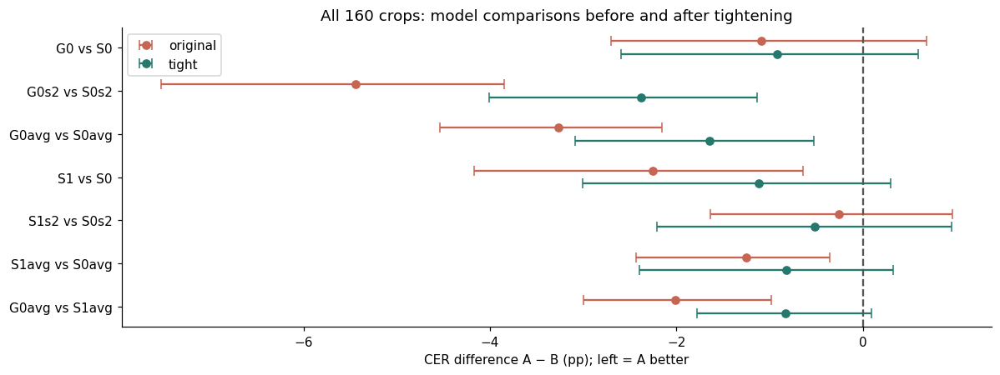

**Reading:** on the original crops G0 beat S0 by 3.3 points (mean of seeds); on the tightened crops by **1.6 points** (95% interval -3.1 .. -0.5). Seed 2 shows a clear gain; seed 1 is smaller and its interval crosses 0. So **about half of G0's earlier advantage disappears once the writing is a sensible size**; a smaller advantage remains in both seeds' direction. S1 vs S0 on tightened crops is not clear (interval crosses 0). This set has already informed development, so these are exploratory comparisons.

In [13]:
keys = [('G0', 'S0'), ('G0s2', 'S0s2'), ('G0avg', 'S0avg'), ('S1', 'S0'), ('S1s2', 'S0s2'), ('S1avg', 'S0avg'), ('G0avg', 'S1avg'), ('S0s2', 'S0'), ('G0s2', 'G0')]
def comp_table(scope):
    c = RM['comparisons'][scope]; rows_ = []
    for a, b in keys:
        r = {'A vs B': f'{a} vs {b}'}
        for arm in ['tight', 'original']:
            v = c[f'{a} vs {b} | {arm}']
            r[f'{arm}: diff (pp)'] = round(100*v['diff'], 2); r[f'{arm}: 95% interval'] = f"{100*v['ci'][0]:+.2f} .. {100*v['ci'][1]:+.2f}"
            r[f'{arm}: A better / worse'] = f"{v['better']} / {v['worse']}"
        rows_.append(r)
    return pd.DataFrame(rows_).set_index('A vs B')
for scope in ['all 160', '156 excl. flagged']:
    display(Markdown(f'**{scope} crops**')); display(comp_table(scope))

c = RM['comparisons']['all 160']; show_keys = keys[:7]
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (a, b) in enumerate(show_keys):
    for arm, off, col in [('original', -.15, '#c56552'), ('tight', .15, '#26786c')]:
        v = c[f'{a} vs {b} | {arm}']; d_ = 100*v['diff']; lo, hi = 100*v['ci'][0], 100*v['ci'][1]
        ax.errorbar(d_, i + off, xerr=[[d_ - lo], [hi - d_]], fmt='o', color=col, capsize=4, label=arm if i == 0 else None)
ax.axvline(0, color='#555', linestyle='--')
ax.set(yticks=range(len(show_keys)), yticklabels=[f'{a} vs {b}' for a, b in show_keys],
       xlabel='CER difference A − B (pp); left = A better', title='All 160 crops: model comparisons before and after tightening')
ax.invert_yaxis(); ax.legend(); fig.tight_layout(); plt.show()
g_t, g_o = c['G0avg vs S0avg | tight'], c['G0avg vs S0avg | original']
display(Markdown(f"**Reading:** on the original crops G0 beat S0 by {100*-g_o['diff']:.1f} points (mean of seeds); on the tightened crops by "
                 f"**{100*-g_t['diff']:.1f} points** (95% interval {100*g_t['ci'][0]:+.1f} .. {100*g_t['ci'][1]:+.1f}). Seed 2 shows a clear gain; "
                 f"seed 1 is smaller and its interval crosses 0. So **about half of G0's earlier advantage disappears once the writing is a sensible size**; "
                 "a smaller advantage remains in both seeds' direction. S1 vs S0 on tightened crops is not clear (interval crosses 0). "
                 "This set has already informed development, so these are exploratory comparisons."))

In [14]:
display(Markdown('**By margin group** (mean of seeds; CER %, original → tight)'))
gr = RM['groups']
display(pd.DataFrame([{'group': g_, 'crops': gr[g_]['S0avg']['n'], **{f'{m} original → tight': f"{100*gr[g_][m]['cer_original']:.1f} → {100*gr[g_][m]['cer_tight']:.1f}" for m in AVG}}
                      for g_ in ['large margin', 'middle', 'control', 'flagged']]).set_index('group'))

**By margin group** (mean of seeds; CER %, original → tight)

,crops,S0avg original → tight,S1avg original → tight,G0avg original → tight
group,,,,
large margin,51,39.1 → 9.0,35.9 → 6.1,35.3 → 6.2
middle,57,14.0 → 6.3,13.2 → 5.6,11.0 → 5.7
control,48,25.9 → 19.5,25.9 → 20.4,22.7 → 17.7
flagged,4,41.0 → 31.5,43.9 → 35.8,42.5 → 32.3


### 7.3 What remains wrong after tightening

These crops still have **at least 15% CER on the tightened input for all six readers**. Each panel shows the tightened crop and the six readings, coloured against the label.

**26 crops** remain hard for all six readers after tightening (of 160). Groups: control: 15, large margin: 5, middle: 4, flagged: 2

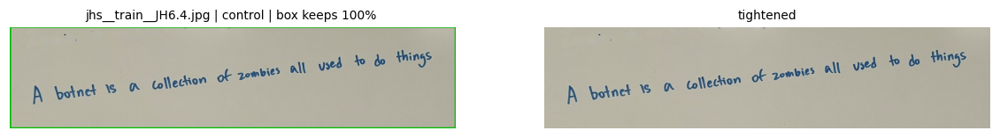

S0,orig 61%,a botnet is a collectioh ot zombwes ao tu ed to donthing.
,tight 61%,a botnet is a collectioh ot zombwes ao tu ed to donthing.
S0s2,orig 58%,a bntnet is e collectien of nombses ale useo ta se thing.
,tight 58%,a bntnet is e collectien of nombses ale useo ta se thing.
S1,orig 65%,a botnetlts a collectioe of zombies all used to du f ing.
,tight 65%,a botnetlts a collectioe of zombies all used to du f ing.
S1s2,orig 72%,a botnet is a collection ol zomties all usedyrn dont ing.
,tight 72%,a botnet is a collection ol zomties all usedyrn dont ing.
G0,orig 58%,a bontet is a collection of zombtes ale used to de thing.
,tight 58%,a bontet is a collection of zombtes ale used to de thing.
G0s2,orig 61%,a botnet is a colle tien of zombies all useo to di things


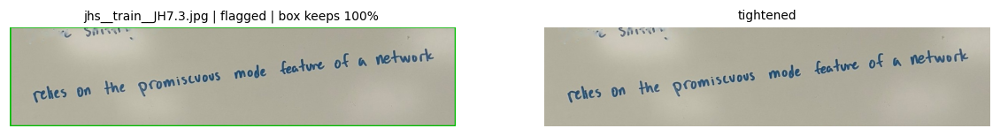

S0,orig 53%,telhes on the pramism ous mbvev ioture of nt networt
,tight 53%,telhes on the pramism ous mbvev ioture of nt networt
S0s2,orig 61%,relihs en the prtpatcioue mode fea i e of ae atwure
,tight 61%,relihs en the prtpatcioue mode fea i e of ae atwure
S1,orig 63%,reohcs on the premteco vo vods ivio tb fo of uatwure
,tight 63%,reohcs on the premteco vo vods ivio tb fo of uatwure
S1s2,orig 67%,rtmoks on the t aeiscue m mai eiei rie of n notwure
,tight 67%,rtmoks on the t aeiscue m mai eiei rie of n notwure
G0,orig 57%,telihs on the promiscuore mode feature w eb net ore
,tight 57%,telihs on the promiscuore mode feature w eb net ore
G0s2,orig 57%,relics sn the p e reimom s iode featu e of a networe


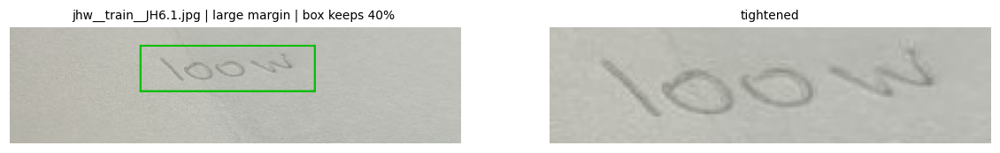

S0,orig 75%,1bow
,tight 125%,toosd
S0s2,orig 75%,ioow
,tight 100%,1ooin
S1,orig 75%,1oow
,tight 25%,100u
S1s2,orig 75%,1oow
,tight 25%,100s
G0,orig 100%,100w
,tight 50%,1o0w
G0s2,orig 75%,voow


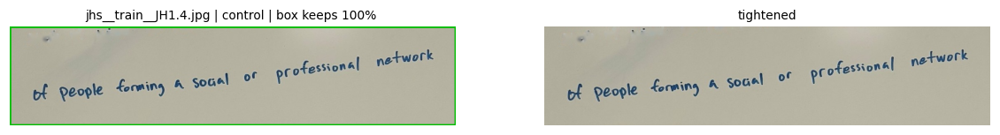

S0,orig 52%,of people formin n a social or profescffnaltnetwore
,tight 52%,of people formin n a social or profescffnaltnetwore
S0s2,orig 56%,oo people forminin a socialuta profess fnal netwurt
,tight 56%,oo people forminin a socialuta profess fnal netwurt
S1,orig 50%,of people fo oing o soc araoa professio al a twtort
,tight 50%,of people fo oing o soc araoa professio al a twtort
S1s2,orig 60%,of people forming a senidi or prop s tringn fnetwurt
,tight 60%,of people forming a senidi or prop s tringn fnetwurt
G0,orig 58%,of prople foto ng e social or orofessiorfe netwure
,tight 58%,of prople foto ng e social or orofessiorfe netwure
G0s2,orig 50%,of people fortinota social or professional nwtwart


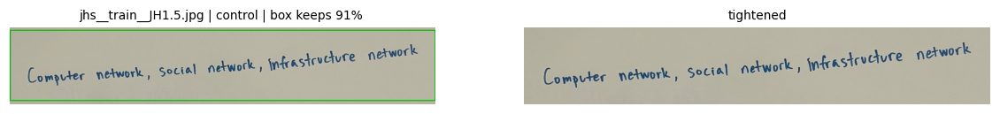

S0,orig 54%,computer notworkr soeral netre nr iniuietrectutnenetentwrk
,tight 52%,comepter netwoert soc al ietw rkw infiustneotuutnenetentok
S0s2,orig 62%,computer motwmrke soceal netw rke ie ntetr ttet tneectrle
,tight 62%,"computetr metworke soca ln ret ork, inftintruetunetnetarlke"
S1,orig 57%,"computer notmork, socra are nark, rv rastrert te te nture"
,tight 50%,"computer metwotet ec caca a network, infrastr ttu te network"
S1s2,orig 55%,computer notwopet sea al retw rlr wierestruituntrntreorl
,tight 52%,computer net ort etasiag ietw rte wts eiurneture nereork
G0,orig 59%,computer motworbe eocial networke infre true ere networke
,tight 55%,computer netwotey soce e oet orke iteraseructure netwurs
G0s2,orig 59%,"computer network, socilr retw r r r t t tr fture network"


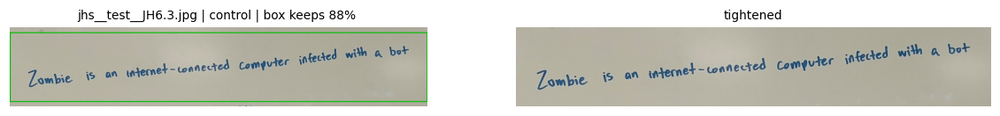

S0,orig 62%,zomtie is on intero t-c tne oed coereter ithec en with atout
,tight 55%,zomtie to an internet-con ec ed comea ece cie tind hn hen bot
S0s2,orig 50%,zomtie is anaenternat-coene ted computertinfected with e tot
,tight 50%,ioamie is an inteinet-coenecned compe er ieceit d with e bot
S1,orig 58%,iomtie is an intern t- e n i er coercnis infefted with f bot
,tight 57%,iomtie is an intaunet-co nected coecetercecies ed et h af bout
S1s2,orig 63%,zomtie is oe inter et-conne ted computea ieiecie adn t nt out
,tight 55%,zambie is an intne tet-eieaected computer infected withnt out
G0,orig 58%,zomhie is on internet- onnected computer ie ec ed rith a bet
,tight 55%,iionmlie is an inte net-con ecred computer infecoed with e bot
G0s2,orig 60%,aomtis it an internet-connected computertente oed withta bat


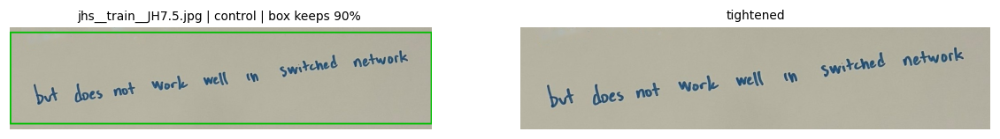

S0,orig 62%,bet hoes not work wrke ie sveotu nuntuntuek
,tight 62%,hot hoes mot work weorkiel witeveo nentntowne
S0s2,orig 55%,bet dors nat woae well ie sei sn ifnetwovk
,tight 48%,but does not a ae weae io e it hednuetwovk
S1,orig 67%,beu ders nos tork weoveie sei h nutt utowis.
,tight 43%,but does not wor eae s ie suetche t utworke
S1s2,orig 57%,beut does noe woih keie we i ingindtnetiouiky
,tight 62%,bet does moet wpae eike we hehctintuntiowurk
G0,orig 55%,bou does oet wort well ie switc ed i tworks
,tight 57%,bos does not obre wvil ie seitched i twurke
G0s2,orig 50%,ben boes nlt works be b ie switchet netwi s


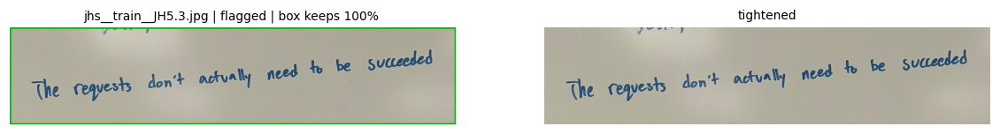

S0,orig 46%,the requests don't o noende noed to be ece coeded
,tight 46%,the requests don't o noende noed to be ece coeded
S0s2,orig 48%,the reqpects doe t actuallyentlt ts bs sseceeded
,tight 48%,the reqpects doe t actuallyentlt ts bs sseceeded
S1,orig 52%,the requests don't actualitaieni t db scsuce uces
,tight 52%,the requests don't actualitaieni t db scsuce uces
S1s2,orig 44%,the reqpests ton'e actualle wend do be euce eded
,tight 44%,the reqpests ton'e actualle wend do be euce eded
G0,orig 60%,the requests don't actually need to in suavneded
,tight 60%,the requests don't actually need to in suavneded
G0s2,orig 40%,the requests don't actual a ndld td to suaceeded


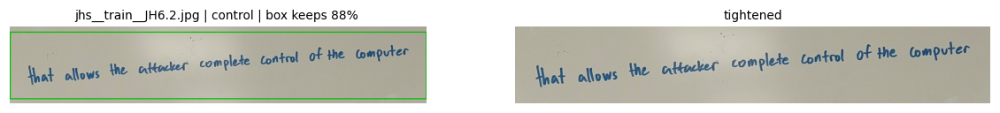

S0,orig 54%,that allows the st ter rme mrevte cohtroe t o hrnromputer
,tight 46%,heat allows t e attackerncompeovhevtr co trol of the computer
S0s2,orig 51%,that allows the ateacker campl pe coetre tot the coaputer
,tight 44%,bhat allows the ateacher c mp o pe cectre tot t e computer
S1,orig 47%,that allows tse auae ncpr crmecehe tcs trol oe tho computer
,tight 37%,that allows the e tacker c cpeovme cte col of tho computer
S1s2,orig 54%,that allowr the attheterbe epeape cont ol df the nt outer
,tight 47%,that allows the attache apo pleolecontroogof tnt comquter
G0,orig 58%,hhat altowo the attacker complese controleoe the apuputer
,tight 49%,that allows the at acker compaete coatroe oe too compuuter
G0s2,orig 53%,that allows the attacker complete control of the computer


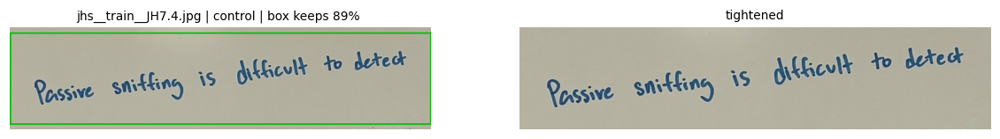

S0,orig 51%,possive snifting is diftotdot te detect
,tight 46%,possive snifting is difdicto otf e etect
S0s2,orig 44%,passive smifting in difticult ts detest
,tight 41%,passive snitting is di diotit tot etect
S1,orig 44%,passive smifting is difti t t o o e detest
,tight 41%,passive smifting is ditit t ttct te detest
S1s2,orig 54%,passive snisting id oif isiogoto detiet
,tight 49%,passive smifsingtis difoicul iuo dot et
G0,orig 31%,paosive snifting is ditticult to dedect
,tight 38%,peosive snifting ig dfifitfult to dedect
G0s2,orig 38%,padsive sniftingi is difsicultito deteot


Remaining names: jhs__train__JH5.2.jpg, jhw__test__JH30.2.jpg, jhs__train__JH5.4.jpg, jhs__train__JH1.1.jpg, jhs__train__JH6.6.jpg, ds__train__1.1.1.jpg, jhw__train__JH19.1.jpg, jhw__test__JH5.1.jpg, jhs__train__JH4.3.jpg, jhs__train__JH6.5.jpg, jhw__train__JH23.2.jpg, ds__test__7.1.1.jpg, jhs__train__JH7.1.jpg, jhw__train__JH22.1.jpg, jhw__train__JH17.3.jpg, ds__test__1.4.2.jpg

In [15]:
cr = {x['name']: x for x in RM['crops']}
def show_models(name, models=MODELS, arm='t', title=''):
    x = cr[name]; o, t_ = load(name)
    fig, axs = plt.subplots(1, 2, figsize=(13, 1.6), gridspec_kw=dict(width_ratios=[o.width / o.height, t_.width / t_.height]))
    axs[0].imshow(overlay(name)); axs[1].imshow(t_); [a.axis('off') for a in axs]
    axs[0].set_title(f'{name} | {x["group"]} | box keeps {x["kept_h"]:.0%} {title}', fontsize=9); axs[1].set_title('tightened', fontsize=9); plt.show()
    h = f'<p style="margin:0"><b>label:</b> {html.escape(x["label"])}</p><table style="font:13px monospace">'
    for m in models:
        mm = x['m'][m]
        h += (f'<tr><td>{m}</td><td>orig {mm["o"]["cer"]:.0%}</td><td>{coloured(x["label"], mm["pred_original"])}</td></tr>'
              f'<tr><td></td><td>tight {mm["t"]["cer"]:.0%}</td><td>{coloured(x["label"], mm["pred_tight"])}</td></tr>')
    display(HTML(h + '</table>'))
pers = sorted(RM['persistent_tight'], key=lambda n: -np.mean([cr[n]['m'][m]['t']['cer'] for m in MODELS]))
display(Markdown(f'**{len(pers)} crops** remain hard for all six readers after tightening (of 160). Groups: '
                 + ', '.join(f'{k}: {v}' for k, v in pd.Series([cr[n]['group'] for n in pers]).value_counts().items())))
for n in pers[:10]: show_models(n)
display(Markdown('Remaining names: ' + ', '.join(pers[10:])))

### 7.4 Regressions: crops that got worse when tightened

A crop is a regression for a model if its tightened reading has a higher CER than its original reading. The table counts them per model; below, every crop that regressed for **two or more** models is shown with all six readings (original and tight).

,S0,S0s2,S1,S1s2,G0,G0s2
regressions (of 160),13,9,10,11,12,14


**14 crops regressed for 2+ models**; 32 regressed for exactly one model (listed at the end).

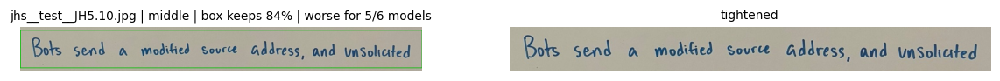

S0,orig 2%,"bots send a modified source address, and unsolicited"
,tight 8%,"bots send a modiftied source address, and unsolicuted"
S0s2,orig 0%,"bots send a modified source address, and unsolicited"
,tight 4%,"bots send a moditied source address, and unsolicated"
S1,orig 2%,"bots send a moditied source address, and unsolicited"
,tight 4%,"bots send a moditied source address, and unsolicited"
S1s2,orig 0%,"bots send a modified source address, and unsolicited"
,tight 4%,"bots send a moditied source address, and unsolicited"
G0,orig 4%,"bots send a moditied source address, and unsolicited"
,tight 2%,"bots send a modified source address, and unsolicated"
G0s2,orig 0%,"bots send a modified source address, and unsolicited"


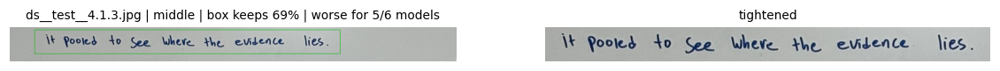

S0,orig 5%,it poolet to see where the evitence lies.
,tight 5%,it pooled to see where the evidence. lies.
S0s2,orig 2%,it pooled to see where the evitence lies.
,tight 5%,it pooied to see wheve the evidence lies.
S1,orig 5%,it poolet to see where the evitence lies.
,tight 7%,it pooied to see wheve the evidence. lies.
S1s2,orig 5%,it poolet to see where the evitence lies.
,tight 7%,1t pooled to see wheve the evidence. lies.
G0,orig 0%,it pooled to see where the evidence lies.
,tight 2%,it pooled to see wheve the evidence lies.
G0s2,orig 2%,it pooled to see where the evilence lies.


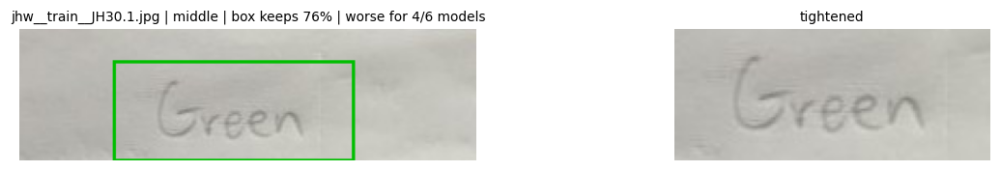

S0,orig 0%,green
,tight 20%,gveen
S0s2,orig 0%,green
,tight 20%,gveen
S1,orig 20%,greoen
,tight 0%,green
S1s2,orig 0%,green
,tight 0%,green
G0,orig 0%,green
,tight 20%,groen
G0s2,orig 0%,green


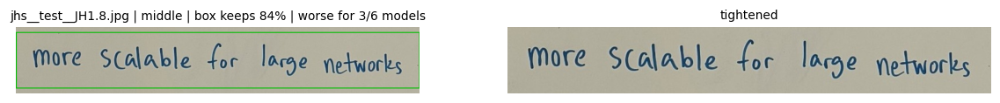

S0,orig 3%,more scalable for large networkes
,tight 6%,more scalable for large networles
S0s2,orig 6%,more scalable for large networles
,tight 3%,more scalable for large networkes
S1,orig 0%,more scalable for large networks
,tight 0%,more scalable for large networks
S1s2,orig 0%,more scalable for large networks
,tight 9%,more scalable for large networles.
G0,orig 0%,more scalable for large networks
,tight 0%,more scalable for large networks
G0s2,orig 0%,more scalable for large networks


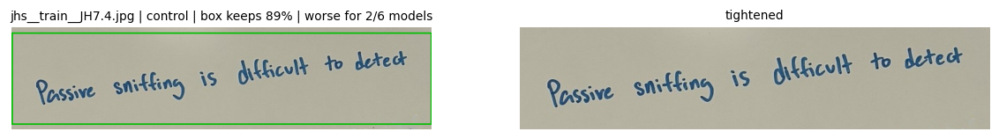

S0,orig 51%,possive snifting is diftotdot te detect
,tight 46%,possive snifting is difdicto otf e etect
S0s2,orig 44%,passive smifting in difticult ts detest
,tight 41%,passive snitting is di diotit tot etect
S1,orig 44%,passive smifting is difti t t o o e detest
,tight 41%,passive smifting is ditit t ttct te detest
S1s2,orig 54%,passive snisting id oif isiogoto detiet
,tight 49%,passive smifsingtis difoicul iuo dot et
G0,orig 31%,paosive snifting is ditticult to dedect
,tight 38%,peosive snifting ig dfifitfult to dedect
G0s2,orig 38%,padsive sniftingi is difsicultito deteot


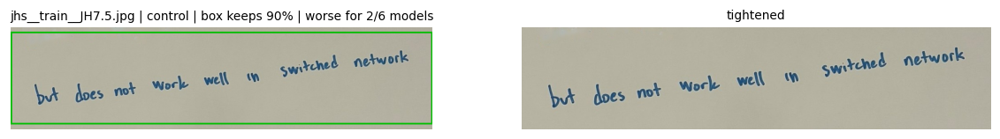

S0,orig 62%,bet hoes not work wrke ie sveotu nuntuntuek
,tight 62%,hot hoes mot work weorkiel witeveo nentntowne
S0s2,orig 55%,bet dors nat woae well ie sei sn ifnetwovk
,tight 48%,but does not a ae weae io e it hednuetwovk
S1,orig 67%,beu ders nos tork weoveie sei h nutt utowis.
,tight 43%,but does not wor eae s ie suetche t utworke
S1s2,orig 57%,beut does noe woih keie we i ingindtnetiouiky
,tight 62%,bet does moet wpae eike we hehctintuntiowurk
G0,orig 55%,bou does oet wort well ie switc ed i tworks
,tight 57%,bos does not obre wvil ie seitched i twurke
G0s2,orig 50%,ben boes nlt works be b ie switchet netwi s


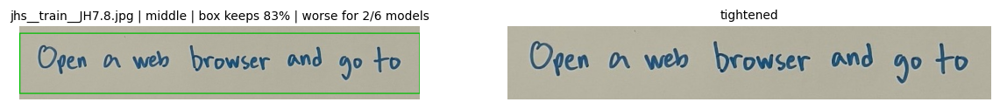

S0,orig 0%,open a web browser and go to
,tight 4%,open a web browser and go to
S0s2,orig 7%,open an webs browser and go to
,tight 7%,open a wehs browser and go to
S1,orig 0%,open a web browser and go to
,tight 0%,open a web browser and go to
S1s2,orig 0%,open a web browser and go to
,tight 4%,open a weh browser and go to
G0,orig 0%,open a web browser and go to
,tight 0%,open a web browser and go to
G0s2,orig 4%,open an web browser and go to


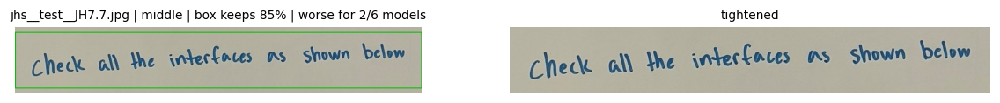

S0,orig 5%,checke all the interfaces ns shown below
,tight 8%,checle all the interfaces ns shown below
S0s2,orig 13%,check all the interfaces os shown becloow
,tight 10%,checle all the interfaces ns shown bclow
S1,orig 10%,check all the interfaces ns shown below
,tight 3%,check all the interfaces ns shown below
S1s2,orig 5%,check all the interfaces ns shown below
,tight 5%,checl all the interfaces ns shown below
G0,orig 8%,checke all the interfaces ns shown below
,tight 5%,check all the interfaces os shown bolow
G0s2,orig 3%,check all the interfaces ns shown below


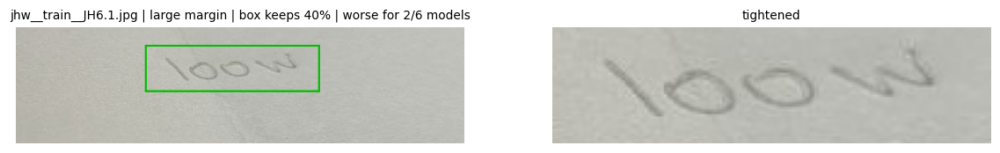

S0,orig 75%,1bow
,tight 125%,toosd
S0s2,orig 75%,ioow
,tight 100%,1ooin
S1,orig 75%,1oow
,tight 25%,100u
S1s2,orig 75%,1oow
,tight 25%,100s
G0,orig 100%,100w
,tight 50%,1o0w
G0s2,orig 75%,voow


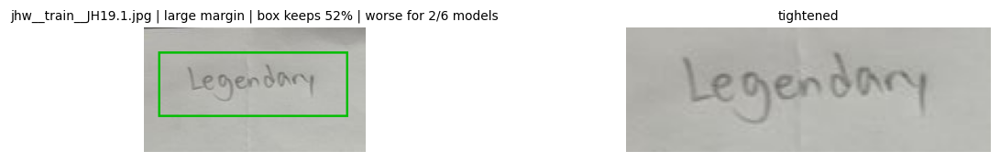

S0,orig 44%,legehdaong
,tight 33%,legendoin
S0s2,orig 44%,legendiong
,tight 22%,legendain
S1,orig 44%,legendrmng
,tight 33%,legeindarn
S1s2,orig 33%,"legenodarp,"
,tight 33%,legendann
G0,orig 33%,legendaing
,tight 56%,legeindinin
G0s2,orig 22%,legendirp


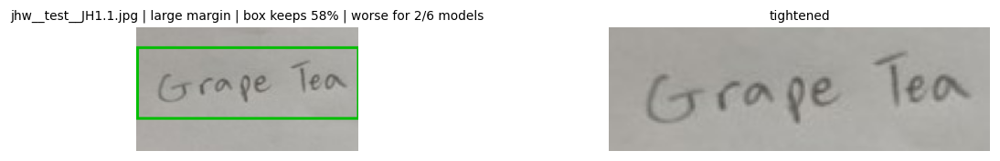

S0,orig 0%,grape tea
,tight 11%,grape ted
S0s2,orig 0%,grape tea
,tight 0%,grape tea
S1,orig 11%,grape toa
,tight 0%,grape tea
S1s2,orig 0%,grape tea
,tight 11%,grape ted
G0,orig 11%,grape toa
,tight 0%,grape tea
G0s2,orig 0%,grape tea


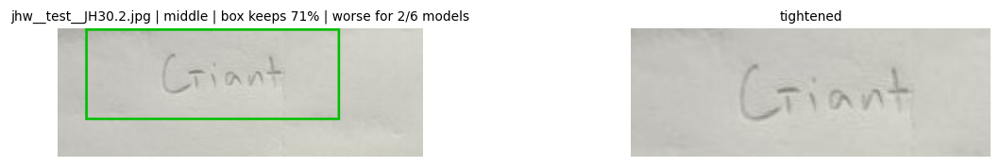

S0,orig 60%,chiont
,tight 40%,ctiant
S0s2,orig 40%,ctiant
,tight 40%,criant
S1,orig 20%,ciant
,tight 40%,ctiant
S1s2,orig 40%,criant
,tight 40%,criant
G0,orig 40%,criant
,tight 40%,ctiant
G0s2,orig 0%,giant


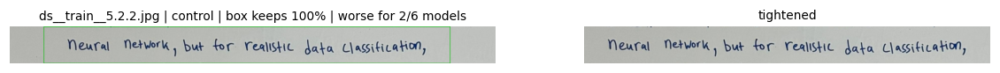

S0,orig 4%,"neural network, but tor realistic data classitication,"
,tight 4%,"neural network, but tor realistic data classitication,"
S0s2,orig 4%,"neural network, but tor realistic data classitication,"
,tight 6%,"neural network, but tor realistic data cclassitication,"
S1,orig 4%,"neural network, but tor realistic data classitication,"
,tight 4%,"neural network, but tor realistic data classitication,"
S1s2,orig 2%,"neural network, but for realistic data classitication,"
,tight 4%,"neural network, but tor realistic data classitication,"
G0,orig 4%,"neural network, but tor realistic data classitication,"
,tight 4%,"neural network, but tor realistic data classitication,"
G0s2,orig 4%,"neural network, but tor realistic data classitication,"


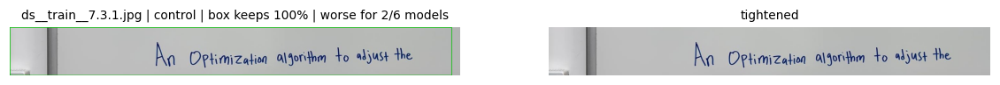

S0,orig 3%,an optimization algorithm to adjust the
,tight 3%,an optimization algorithm to adjust the
S0s2,orig 8%,an optimization algorithm to adjusts ths
,tight 15%,an optimization ailgorithm to adjust the
S1,orig 15%,an optimization algorithm to adjs t the
,tight 15%,an optimization aigorithm to adjust the
S1s2,orig 15%,e an ooptimization algorithm to adjus t the
,tight 5%,an optimization algorithm to adjus t the
G0,orig 10%,an ooptimization algorithm to adjust the
,tight 10%,an ooptimization algorithm to adjust the
G0s2,orig 8%,an optimization algorithm to adjust the


Regressed for one model only: jhs__train__JH2.2.jpg (G0), jhs__train__JH3.4.jpg (G0s2), jhs__train__JH3.8.jpg (S0), jhs__train__JH4.1.jpg (S0), jhs__train__JH4.6.jpg (S1s2), jhs__train__JH4.9.jpg (S1), jhs__train__JH5.2.jpg (S1), jhs__train__JH5.4.jpg (G0), jhs__train__JH5.6.jpg (G0s2), jhs__train__JH5.7.jpg (G0), jhs__train__JH6.8.jpg (S1s2), jhs__train__JH7.1.jpg (S0s2), jhs__train__JH7.10.jpg (S0), jhw__train__JH7.1.jpg (S1), jhw__train__JH17.3.jpg (S1), jhw__train__JH18.1.jpg (S0), jhw__train__JH18.2.jpg (S1s2), jhw__train__JH22.1.jpg (G0), jhw__train__JH23.1.jpg (G0), jhw__test__JH20.2.jpg (S0), ds__train__1.4.3.jpg (G0s2), ds__train__5.1.1.jpg (S0), ds__train__5.1.2.jpg (G0), ds__test__5.3.1.jpg (G0), ds__train__5.3.3.jpg (S1), ds__train__5.4.1.jpg (S0s2), ds__train__5.4.2.jpg (S1), ds__train__5.4.3.jpg (S1), ds__train__6.1.2.jpg (S1s2), ds__train__6.2.3.jpg (G0s2), ds__test__6.4.2.jpg (G0s2), ds__train__6.4.3.jpg (S0s2)

In [16]:
reg = RM['regressions']
cnt = pd.Series({n: sum(n in reg[m] for m in MODELS) for n in cr})
display(pd.DataFrame({'regressions (of 160)': {m: len(reg[m]) for m in MODELS}}).T)
multi = cnt[cnt >= 2].sort_values(ascending=False)
display(Markdown(f'**{len(multi)} crops regressed for 2+ models**; {int((cnt == 1).sum())} regressed for exactly one model (listed at the end).'))
for n, k in multi.items(): show_models(n, title=f'| worse for {k}/6 models')
display(Markdown('Regressed for one model only: ' + ', '.join(f"{n} ({[m for m in MODELS if n in reg[m]][0]})" for n in cnt[cnt == 1].index)))

### 7.5 What this adds

- **Tightening helps every reader** by about 11–15 points of CER, with intervals below 0 for all six. Deletions fall by about two-thirds for every model. The crop-scale effect is not specific to S1.
- **G0 vs S0:** G0's advantage on these writers **roughly halves** once the text is a sensible size (about 3.3 → 1.7 points, mean of seeds). It remains in the same direction for both seeds, but seed 1's interval crosses 0. Part of G0's earlier new-writer gain was robustness to small writing; part may be genuine.
- **S1 vs S0** on tightened crops is not clear.
- **The 156-crop analysis gives the same picture** as all 160.
- **Remaining errors** (26 crops hard for all six readers after tightening) are now mostly genuine reading problems: unusual letter shapes, faint short words, character confusions. They are no longer explained by text size.

Limits as before: oracle rectangles, JH/DS already used in development, Mac CPU scorer. No training or app change was made.

## 8 · The 26 crops still hard for all six readers after tightening (review, 9 Nov)

**Which crops.** These are the 26 crops with **≥ 15 % CER for every reader** (S0, S0s2, S1, S1s2, G0, G0s2) on the tightened crops (section 7).

**What this section does.**
- Shows every one of the 26: the tight crop, the exact 64-px input S1 receives, the label and all six predictions.
- Groups the failures by what is visible in the images, and backs each group with measurements.

**What changed for this section.**
- One extra S1 run recorded which output position each character comes from: `persistent_review/s1_position_trace.json`.
- No training was run, and the app, the labels and the rectangles were not changed.
- The categories are the assistant's visual judgement; uncertain items are flagged.

Files are in `claude_margin_diagnostic_20261109/persistent_review/`:
- `REVIEW.json`: one row per crop with its category, measurements and notes;
- `sheet_1..7.jpg`;
- `persistent_26.json`.

In [17]:
from IPython.display import Image as IPImage
RV = json.loads((D / 'persistent_review/REVIEW.json').read_text())
rv = pd.DataFrame(RV['rows'])
print(RV['status'])
display(rv.groupby(['category', 'category_description']).agg(crops=('name', 'size'), mean_CER_6=('mean_cer6', 'mean'),
        mean_deletions=('mean_D6', 'mean'), mean_substitutions=('mean_S6', 'mean')).round(2))
display(rv[['category', 'name', 'label', 'mean_cer6', 'mean_D6', 'mean_S6', 'label_chars', 's1_positions', 'need_over_positions',
            'ink_angle_deg', 'ink_extent_over_local_band', 's1_chars_emitted_in_padding', 'note']])

assistant categorisation; uncertain items flagged; labels unchanged


,,crops,mean_CER_6,mean_deletions,mean_substitutions
category,category_description,,,,
A1,Sloped long line in an axis-aligned box: writing compressed in S1 input,16,0.46,11.25,10.01
A2,Long line with a residual blank band (box kept a speck/light patch): writing compressed in S1 input,2,0.34,6.60,5.80
C,"Legible long line, scattered letter confusions",1,0.20,3.70,7.30
D,"Short word, writer-specific letterform read the same wrong way by all six readers",5,0.32,0.10,1.60
E,"Faint, low-contrast, small writing",1,0.37,0.80,2.00
F,Strongly rotated short text (~20 deg),1,0.58,0.30,1.70


,category,name,label,mean_cer6,mean_D6,mean_S6,label_chars,s1_positions,need_over_positions,ink_angle_deg,ink_extent_over_local_band,s1_chars_emitted_in_padding,note
0,A1,jhs__train__JH6.4.jpg,A botnet is a collection of zombies all used t...,0.626,28.2,7.5,57,35.0,1.686,-5.86,4.55,11,
1,A1,jhs__train__JH7.3.jpg,relies on the promiscuous mode feature of a ne...,0.595,12.8,17.0,51,35.9,1.422,-3.37,4.83,16,
2,A1,jhs__train__JH5.3.jpg,The requests don't actually need to be succeeded,0.483,12.2,10.8,48,36.8,1.415,-4.04,4.11,15,
3,A1,jhs__train__JH1.4.jpg,of people forming a social or professional net...,0.543,16.8,9.7,50,36.1,1.412,-5.32,4.66,14,
4,A1,jhs__test__JH6.3.jpg,Zombie is an internet-connected computer infec...,0.533,16.8,14.2,60,47.8,1.277,-4.65,3.57,15,
5,A1,jhs__train__JH6.2.jpg,that allows the attacker complete control of t...,0.439,14.2,9.7,57,49.8,1.186,-4.09,3.00,13,
6,A1,jhs__train__JH7.5.jpg,but does not work well in switched network,0.532,7.5,13.7,42,36.5,1.178,-6.56,3.37,16,
7,A1,jhs__train__JH1.5.jpg,"Computer network, social network, infrastructu...",0.536,12.3,16.3,56,48.4,1.158,-4.03,3.11,13,
8,A1,jhs__train__JH7.4.jpg,Passive sniffing is difficult to detect,0.432,7.7,8.3,39,36.6,1.147,-5.93,2.81,13,
9,A1,jhs__train__JH1.1.jpg,A network is a system of interconnected people,0.399,8.0,9.7,46,43.2,1.087,-4.74,3.39,11,


### 8a · All 26 crops

Crops are ordered from most crowded to least. **How the reader's output positions work:**
- S1 always produces **128 output positions**: the input is padded to 1024 px wide, and each position covers 8 px.
- The model keeps all 128. What changes is how much of the input the resized crop fills. A crop resized to 64 px high and 280 px wide covers only the first 35 positions; the other 93 lie over grey padding.
- **Crowded** = characters needed ÷ positions covered by the text. A value ≥ 1 means fewer than one covered position per character.
- "Characters needed" counts a CTC blank between doubled letters, which is why a doubled letter costs an extra position.

**Each panel shows:**
- top: the tight crop;
- middle: exactly what S1 receives, resized to 64 px high and padded to 1024 px (mid-grey = padding);
- bottom: the label, then the six predictions with CER and substitution/deletion/insertion (S/D/I) counts.

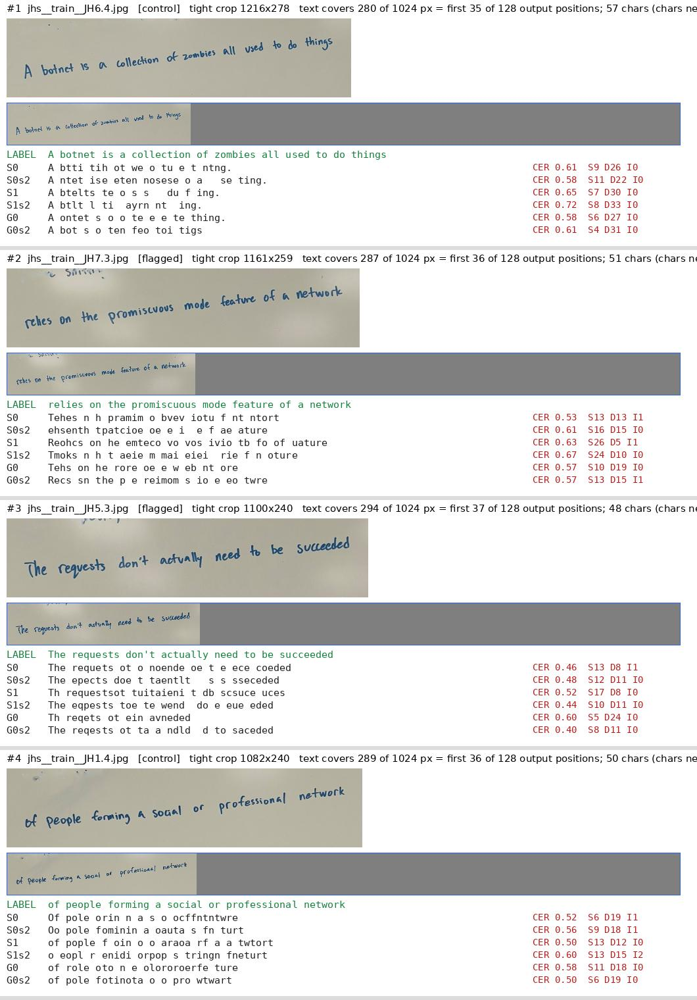

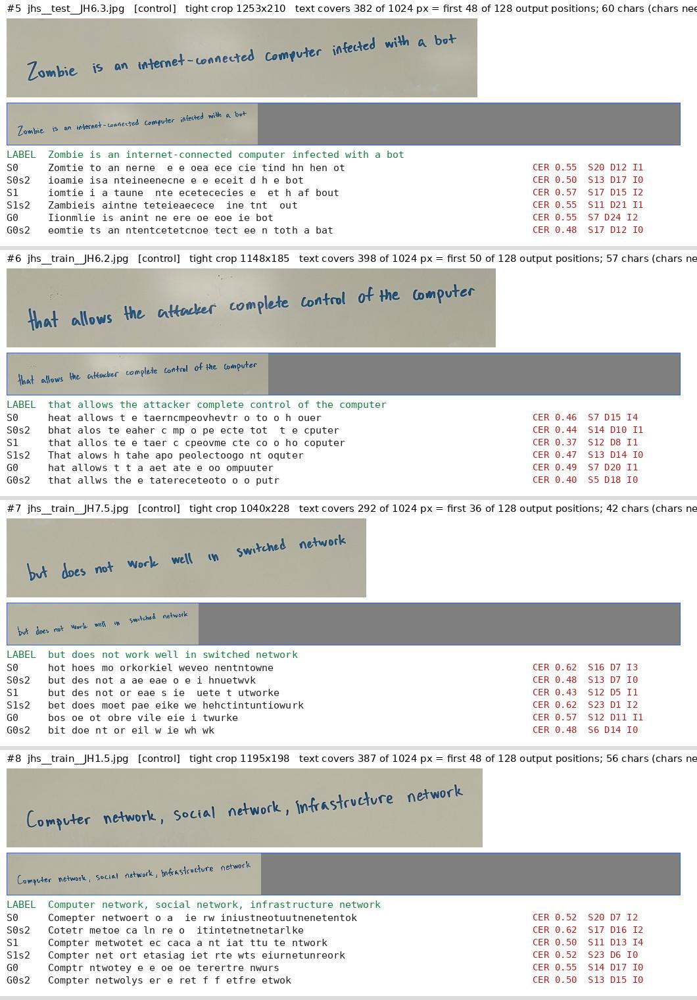

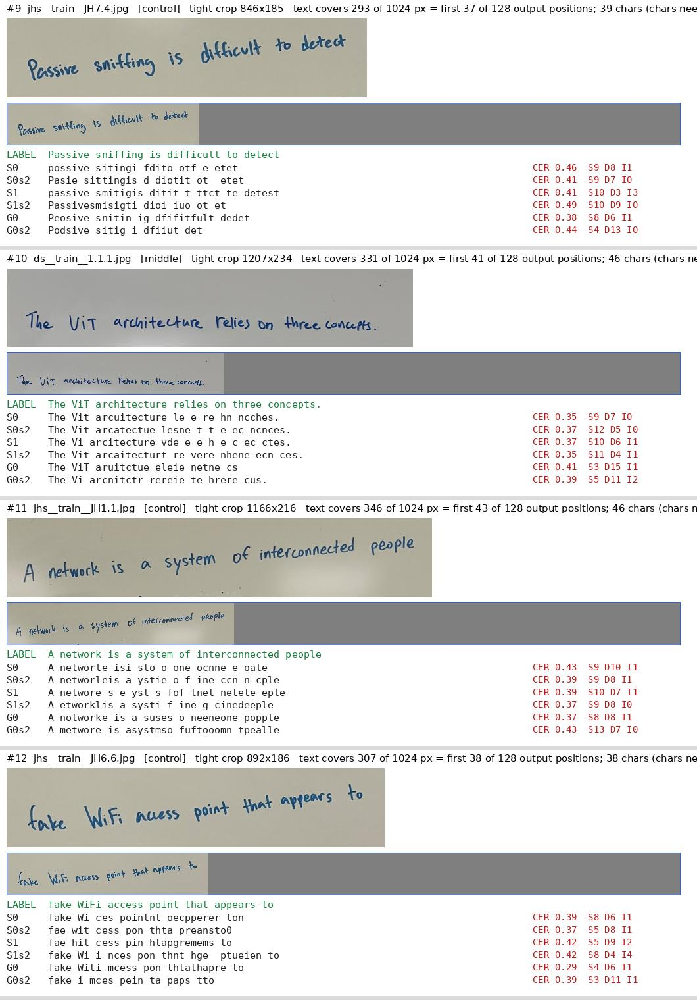

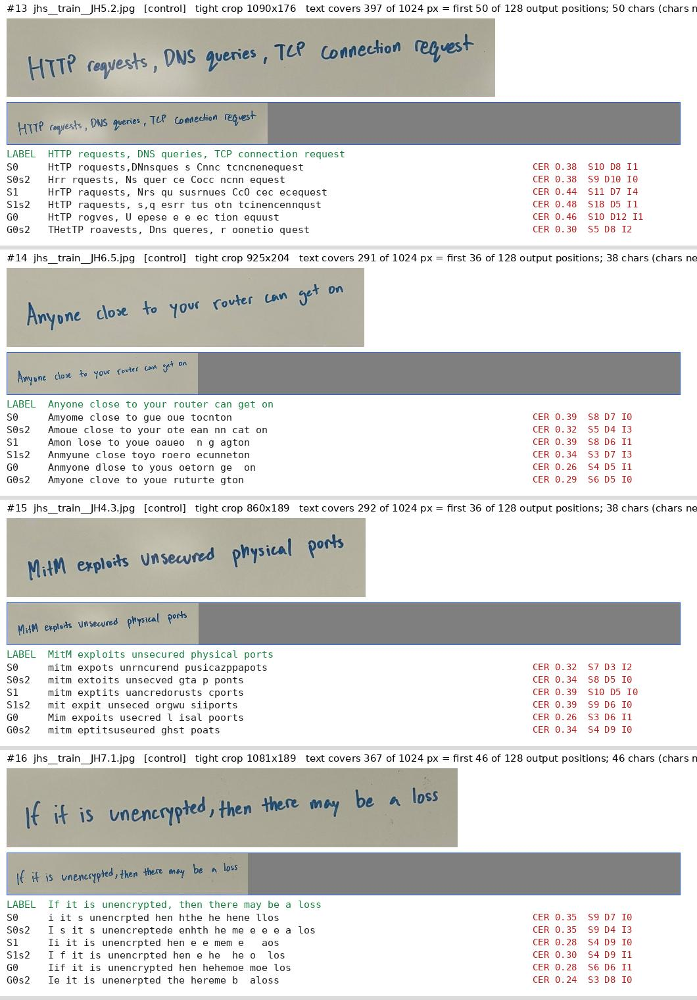

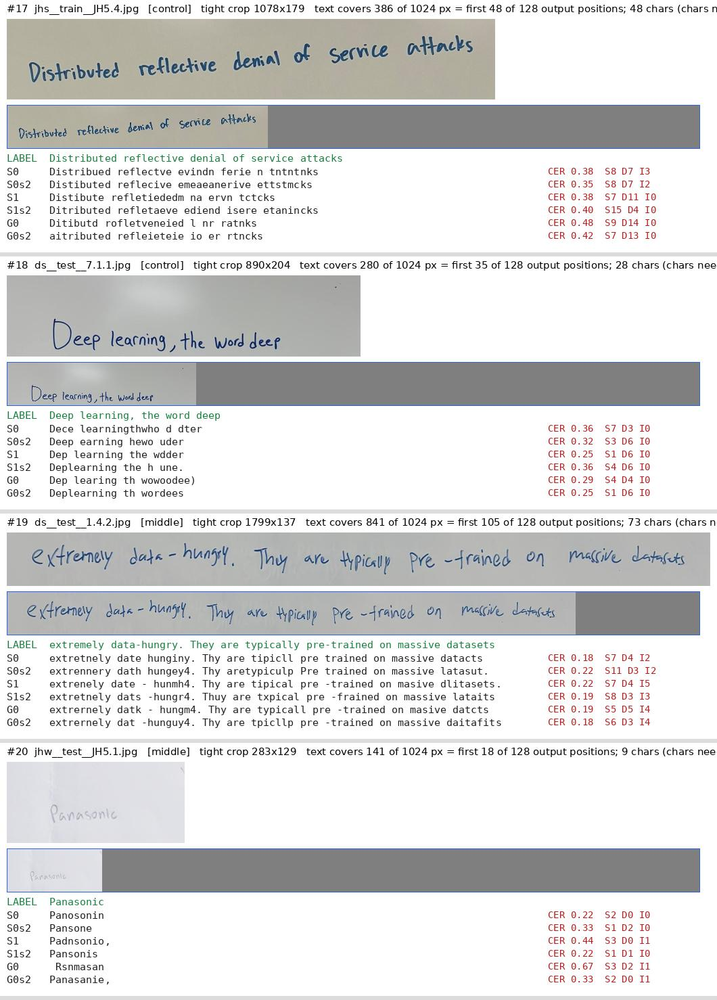

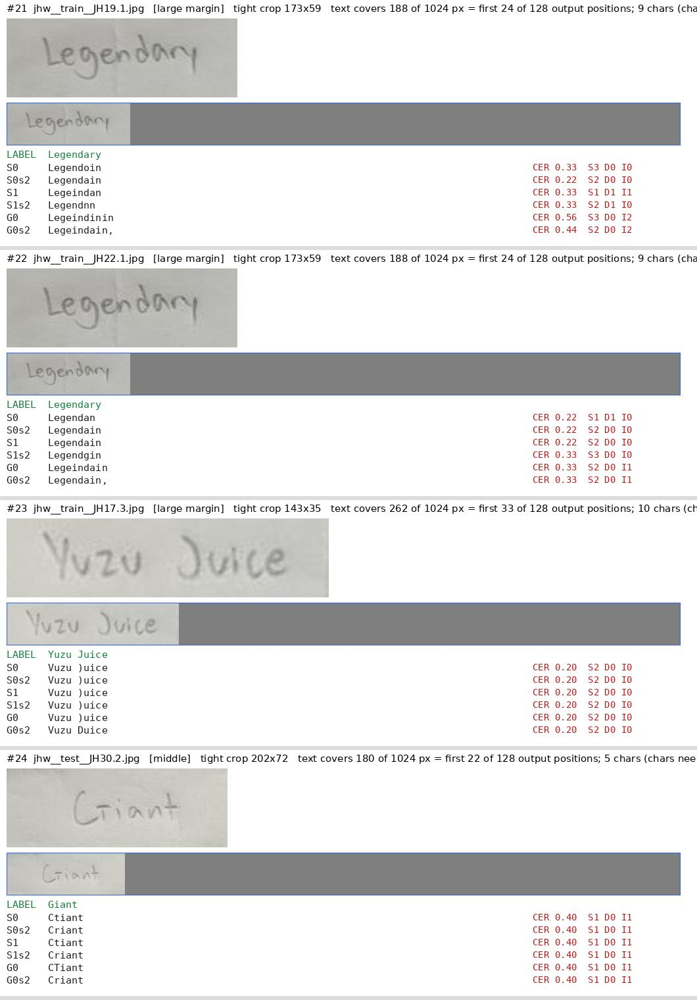

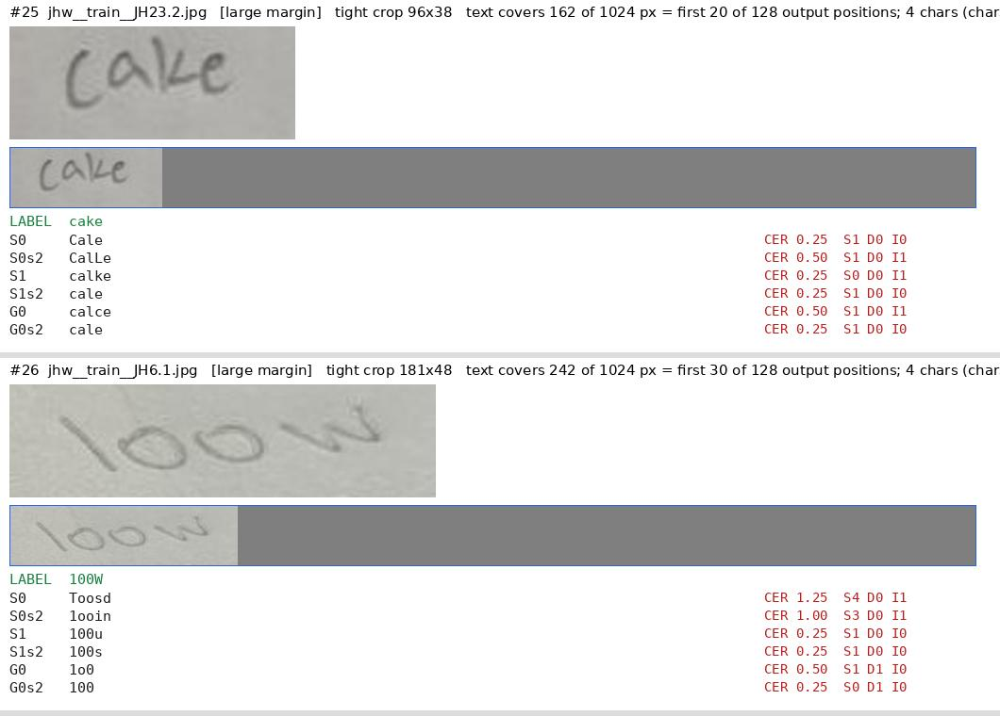

In [18]:
for i in range(1, 8):
    display(IPImage(filename=str(D / f'persistent_review/sheet_{i}.jpg'), width=1000))

### 8b · What the images show

| group | crops | what is visible |
|---|---|---|
| **A1 · sloped long line in an axis-aligned box** | **16** (all JH sentence crops) | The sentence rises 3–7° from left to right. To contain the slope, the upright box is about 3× as tall as the writing band. Squeezed to 64 px, the letters get small and the line gets short: S1 still produces all 128 output positions, but the resized crop covers only the first 35–50 of them, so 38–60 characters must fit there (the rest of the positions lie over padding). Every reader gets the first words right and degrades to the right. Deletions dominate. |
| **A2 · long line with a leftover blank band** | 2 (DS) | The box kept a speck or light patch, so the writing sits in the lower half. Same effect as A1: the writing is compressed in S1's input. |
| C · legible long line, scattered letter confusions | 1 (DS) | m ↔ rn, y ↔ 4. Possible label question ("They" vs written "Thy"). |
| D · short word, unusual letterform read the same wrong way by all six | 5 (JH) | *Legendary* → "Legendain"; *Yuzu Juice* → "Vuzu )uice"; *Giant* → "Ctiant"; *cake* → "cale". The reader mistakes are consistent across all six; one or two wrong characters on a short word already exceed 15 % CER. |
| E · faint and small | 1 | *Panasonic*: very low contrast. |
| F · strongly rotated short text | 1 | *100W* at about 20°. |

**Uncertain diagnoses** (also in the `note` column):
- **Possible label mismatches** (the labels are unchanged; owner to check):
  - JH6.6 *access*: the word may be written *acess*.
  - DS 1.4.2: *They* may be written *Thy*.
  - JH30.2 *Giant*: the G has a T-like bar, so "CTiant" may simply be what is written.
- **Near-duplicates:** JH19.1 and JH22.1 look like the same word photographed twice, so that error counts twice.
- **Mixed causes:**
  - The two A2 crops show both a leftover margin and crowding.
  - *Yuzu Juice* is also a tiny, blurred crop (143 × 35 px).

,long_lines,median_abs_angle,median_extent_over_band,median_need_over_positions,crowded_ge_1,S1_text_in_padding,mean_CER
persistent,,,,,,,
False,106,0.95,1.82,0.62,1,14,0.05
True,19,4.11,3.11,1.14,17,19,0.43


,long_lines,persistent,mean_CER
need_over_positions,,,
"[0.0, 0.5)",9,0,0.043
"[0.5, 0.75)",77,1,0.042
"[0.75, 1.0)",21,1,0.114
"[1.0, 1.25)",13,12,0.390
"[1.25, 9.0)",5,5,0.556


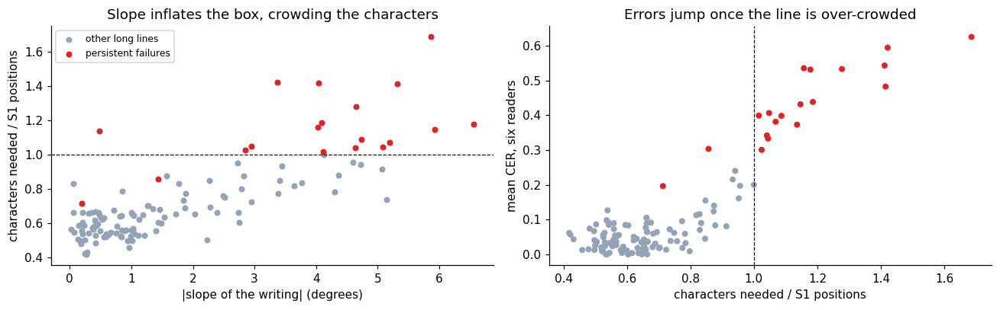

In [19]:
# Evidence for group A: long lines (label >= 25 chars) - persistent failures versus all other long lines
import math, cv2
def ink_mask(gray):
    h, w = gray.shape; k = max(15, (min(h, w) // 3) | 1); k = min(k, 255) | 1
    diff = cv2.subtract(cv2.medianBlur(gray, k), gray); thr = max(10.0, 0.20 * float(np.percentile(diff, 99.5)))
    m = cv2.morphologyEx((diff > thr).astype(np.uint8), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8); keep = [i for i in range(1, n) if st[i, 4] >= max(6, 0.00005 * h * w)]
    return np.isin(lab, keep)
trace = json.loads((D / 'persistent_review/s1_position_trace.json').read_text())
RM = json.loads((D / 'RESULTS_MODELS.json').read_text()); persist = set(RM['persistent_tight'])
MODS = ['S0', 'S0s2', 'S1', 'S1s2', 'G0', 'G0s2']
ll = []
for c in RM['crops']:
    if len(c['label']) < 25:
        continue
    g = cv2.imread(str(D / 'crops_tight' / (Path(c['name']).stem + '.png')), 0); m = ink_mask(g); ys, xs = np.nonzero(m)
    X = np.stack([xs, ys], 1).astype(float); X -= X.mean(0); _, _, vt = np.linalg.svd(X, full_matrices=False)
    ang = (math.degrees(math.atan2(vt[0, 1], vt[0, 0])) + 90) % 180 - 90
    W = g.shape[1]; band = np.median([s.max() - s.min() for s in (ys[(xs >= a * W / 10) & (xs < (a + 1) * W / 10)] for a in range(10)) if len(s) > 20])
    lab = c['label']; need = len(lab) + sum(a == b for a, b in zip(lab, lab[1:]))
    ll.append(dict(name=c['name'], persistent=c['name'] in persist, writer=c['name'].split('__')[0], abs_angle=abs(ang),
                   extent_over_band=(ys.max() - ys.min()) / band, need_over_positions=need / (math.ceil(64 * g.shape[1] / g.shape[0]) / 8),
                   spills=trace[c['name']]['chars_in_padding'] > 0, mean_cer6=np.mean([c['m'][x]['t']['cer'] for x in MODS])))
LL = pd.DataFrame(ll)
display(LL.groupby('persistent').agg(long_lines=('name', 'size'), median_abs_angle=('abs_angle', 'median'),
        median_extent_over_band=('extent_over_band', 'median'), median_need_over_positions=('need_over_positions', 'median'),
        crowded_ge_1=('need_over_positions', lambda s: int((s >= 1).sum())), S1_text_in_padding=('spills', 'sum'), mean_CER=('mean_cer6', 'mean')).round(2))
bins = pd.cut(LL.need_over_positions, [0, .5, .75, 1.0, 1.25, 9], right=False)
display(LL.groupby(bins, observed=True).agg(long_lines=('name', 'size'), persistent=('persistent', 'sum'), mean_CER=('mean_cer6', 'mean')).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for p_, col, lab_ in ((False, '#94a3b8', 'other long lines'), (True, '#dc2626', 'persistent failures')):
    s = LL[LL.persistent == p_]; ax[0].scatter(s.abs_angle, s.need_over_positions, c=col, s=18, label=lab_)
ax[0].axhline(1, ls='--', c='k', lw=.8); ax[0].set_xlabel('|slope of the writing| (degrees)'); ax[0].set_ylabel('characters needed / S1 positions')
ax[0].legend(fontsize=8); ax[0].set_title('Slope inflates the box, crowding the characters')
ax[1].scatter(LL.need_over_positions, LL.mean_cer6, c=np.where(LL.persistent, '#dc2626', '#94a3b8'), s=18)
ax[1].axvline(1, ls='--', c='k', lw=.8); ax[1].set_xlabel('characters needed / S1 positions'); ax[1].set_ylabel('mean CER, six readers'); ax[1].set_title('Errors jump once the line is over-crowded')
plt.tight_layout(); plt.show()

In [20]:
# What S1 does with an over-crowded line: one character per output position ('_' = blank). The input is padded to 1024 px,
# so the text occupies only the first `text_positions` of the 128 positions; the rest is padding.
for n in ['jhs__train__JH1.1.jpg', 'jhs__train__JH6.4.jpg', 'jhs__train__JH3.6.jpg']:
    t = trace[n]
    print(f"{n}: label {[c['label'] for c in RM['crops'] if c['name'] == n][0]!r}")
    print(f"   text occupies {t['text_positions']} of {t['T']} positions; characters emitted inside padding: {t['chars_in_padding']} {t['padding_text']!r}")
    print('   ' + t['per_position'])

jhs__train__JH1.1.jpg: label 'A network is a system of interconnected people'
   text occupies 43.2 of 128 positions; characters emitted inside padding: 11 'netete eple'
   A  neetworee ss  e ystt s   fof ttnnnnet _____________neeeteteee_______________________________________________________  eppplle
jhs__train__JH6.4.jpg: label 'A botnet is a collection of zombies all used to do things'
   text occupies 35.0 of 128 positions; characters emitted inside padding: 11 '  du f ing.'
   A  btteelts    ttee  o     s  s   ____ _____   du     f________________________________________________________________   innng.
jhs__train__JH3.6.jpg: label 'network form the source to the destination'
   text occupies 78.1 of 128 positions; characters emitted inside padding: 0 ''
   ____n_e_t_w_o_rk_   fo_rm__  thhe_  s_o_u_r_ce_  t_o_ t_h_e  d_es_tin_attion____________________________________________________


### 8c · The most common actionable pattern, and one experiment to test it

**Pattern.** 18 of the 26 crops (groups A1 and A2) fail because **the writing reaches S1 compressed**: small letters, too few output positions per character.
- 16 of these are JH sentence lines written on a slope and cut with an upright box.
- Compared with the other long lines:

| | persistent long-line failures | other long lines |
|---|---|---|
| median slope | ≈ 4° | ≈ 1° |
| box height ÷ writing-band height | ≈ 3.1 | ≈ 1.8 |
| crowded (≥ 1 character per output position covered by the text) | 17 of 19 | 1 of 106 |

- S1 runs out of room. In all 16 A1 crops, and in both A2 crops, the end of the sentence is emitted as garbled text **inside the padding** at the right of the canvas.
- This is not unfamiliar handwriting as such. The same writer's flat lines read well (e.g. JH3.6, JH4.8, 0–1 % CER).
- In training data, fewer than 7 % of long lines are this crowded.

The other 8 crops are a mix: letterform confusions on short words, one faint word, one rotated word, and possible label questions. None of these patterns is large enough to act on yet.

**Recommended experiment: rectify the line, then re-tighten (frozen readers, no training).**

- *Inputs:* the same 160 frozen tight crops and labels.
- *Intervention (label-free, images only):*
  1. Estimate the writing's angle from the ink mask (the principal axis, used only for long lines: ink width ≥ 6 × band height).
  2. Rotate the crop so the line is horizontal.
  3. Re-apply the same notebook-14 tight-box rule.
  4. Freeze angles, boxes and a visual check of every changed crop **before** any reading.
  5. Crops with |angle| < 1° stay byte-identical.
- *Readers:* the same six exports and the same Mac scorer.
- *Pre-declared stratum:* long lines with |angle| ≥ 2°, defined from the images alone.
- *Supported only if all three hold:*
  1. The stratum's mean CER (S1, mean of seeds) falls, with a photo-cluster bootstrap CI below 0.
  2. Deletions fall.
  3. The number of crops emitting text into the padding falls.
- *Safety check:* changed crops outside the stratum get no worse than +1 point.
- *Optional mechanism arm:* stretch the *un-rotated* crop horizontally to the same S1 width.
  - If it recovers as much as rectification does, crowding is the mechanism (relevant for the CTC slot count).
  - If only rotation helps, the slope itself matters.

**Why this experiment first.**
- It targets the largest group with a label-free change.
- It reuses everything already frozen.
- It answers whether the remaining "unfamiliar writer" gap on JH sentences is mostly a crop-geometry artifact.

The app's detector already cuts along rotated quads (`quad_crop`), so if this is supported, the next check is whether app crops of JH's sloped lines are already rectified. JH's full photos (`JH_datasetNov5Sentence/Photo1–7.jpg`) make that possible later. That check, and any training change, waits for this result.

## 9 · Straightening experiment: tightened vs straightened vs stretched (9 Nov)

**Question.** Section 8 found that sloped sentence lines in upright boxes reach S1 with the writing compressed. Does straightening them fix the errors? If it does, is the cause the slope itself or the lost horizontal resolution?

**Three versions of the same crops**, read by the same six frozen readers with the same static CPU scorer code:

| arm | what |
|---|---|
| **T** | the existing tightened crops, unchanged |
| **R** | straightened: the original source crop is rotated level, then the notebook-14 tight-box rule is re-applied (all ink kept, same padding) |
| **H** | T stretched horizontally (no rotation) so that, at 64 px high, it is exactly as wide as R |

**Fixed before any reading** (`straighten/PROTOCOL_straighten.json`):
- *Angles:* projection-profile deskew of the ink, taken from the images only.
- *Which crops are processed:* long lines only, meaning ink width ≥ 13 × writing-band height. There is a clean gap between words and short phrases (≤ 12.1) and sentence lines (≥ 13.0).
  - 125 crops are processed.
  - The 35 words and short phrases are byte-identical in all arms.
- *Groups* (by measured slope):
  - **sloped**, |angle| ≥ 2° (n = 40);
  - middle (n = 23);
  - **flat controls**, |angle| < 1° (n = 62), which go through the same rotate-and-recrop steps.
- *Stroke check:* 122 of the 125 crops keep every ink pixel. In the other 3, the lost pixels (0.07–0.11 %) were checked by eye: they are edge residue or specks, not target strokes.
- *Visual check:* all 125 rows are in `straighten/check_sheets/`.
- *Primary rule:* in the sloped group, S1avg (the per-crop mean of the S1 and S1s2 seeds) must have a CER change R − T with a cluster-bootstrap 95 % CI below 0, **and** deletions must fall.
- *Safety:* in the flat controls, the R − T CI upper bound must be ≤ +1 point.
- *Mechanism:* f = (T − H) / (T − R).
  - f ≥ ⅔: horizontal resolution is the main mechanism.
  - f ≤ ⅓: the slope itself matters most.
  - In between: mixed.

Characters predicted over the padding are a secondary diagnostic only. No training was run, and the app, the labels, the rectangles and earlier results were not changed.

**One caveat on arm H.** Its stretch factor comes from R's geometry, so H is a *mechanism control*, not an independent policy.

In [21]:
SD = D / 'straighten'
PS = json.loads((SD / 'PROTOCOL_straighten.json').read_text())
RS = json.loads((SD / 'RESULTS_STRAIGHTEN.json').read_text())
print('Protocol:', PS['status'])
print('T re-read vs saved tightened predictions, mismatches per model:', RS['determinism_T_mismatches'])
rows9 = []
for g, d_ in RS['groups'].items():
    s = d_['S1avg']
    rows9.append({'group': g, 'n': s['n'], 'CER T': s['cer_T'], 'CER R': s['cer_R'], 'CER H': s['cer_H'],
                  'R-T': s['R-T']['diff'], 'R-T 95% CI': f"{100*s['R-T']['ci'][0]:+.1f} … {100*s['R-T']['ci'][1]:+.1f}",
                  'R better/worse': f"{s['R-T']['better']}/{s['R-T']['worse']}",
                  'H-T': s['H-T']['diff'], 'R-H': s['R-H']['diff'], 'R-H 95% CI': f"{100*s['R-H']['ci'][0]:+.1f} … {100*s['R-H']['ci'][1]:+.1f}",
                  'deletions T/R/H': f"{s['D_T']:.0f}/{s['D_R']:.0f}/{s['D_H']:.0f}",
                  'crops with text in padding T/R/H': f"{s['pad_crops_T']}/{s['pad_crops_R']}/{s['pad_crops_H']}"})
T9 = pd.DataFrame(rows9).set_index('group')
for k in ('CER T', 'CER R', 'CER H', 'R-T', 'H-T', 'R-H'):
    T9[k] = (100 * T9[k]).round(2)
display(Markdown('**S1avg (mean of the two S1 seeds), CER in %**')); display(T9)
print('Verdict (pre-declared rules):', RS['verdict'])
print('Crops with >= 15% CER for all six readers, T/R/H:', RS['persistent_ge15_all_six'], '| of the original 26, still persistent:', RS['original_26_after'])

Protocol: frozen BEFORE any reading of the straightened (R) or stretched (H) crops; crops chosen from images only and every changed crop visually checked (check_sheets/, 125 rows)
T re-read vs saved tightened predictions, mismatches per model: {'S0': 0, 'S0s2': 0, 'S1': 0, 'S1s2': 0, 'G0': 0, 'G0s2': 0}


**S1avg (mean of the two S1 seeds), CER in %**

,n,CER T,CER R,CER H,R-T,R-T 95% CI,R better/worse,H-T,R-H,R-H 95% CI,deletions T/R/H,crops with text in padding T/R/H
group,,,,,,,,,,,,
sloped,40,24.85,7.91,7.42,-16.94,-20.8 … -12.2,33/4,-17.43,0.49,-0.3 … +1.4,202/70/68,28/6/7
middle,23,4.72,4.12,3.89,-0.60,-2.6 … +0.9,10/6,-0.83,0.23,-0.2 … +0.7,23/10/10,1/0/0
flat control,62,5.83,5.30,5.29,-0.53,-2.0 … +0.1,20/21,-0.53,0.00,-0.4 … +0.3,40/39/41,5/4/4
flat control (JH only),13,3.80,1.31,1.43,-2.49,-10.5 … -0.1,6/3,-2.37,-0.12,-1.8 … +0.6,2/2/2,1/0/0
all processed (125),125,11.71,5.92,5.72,-5.79,-9.8 … -2.4,63/31,-6.00,0.20,-0.2 … +0.6,264/119/118,34/10/11
all 160,160,10.96,6.43,6.27,-4.53,-7.6 … -1.8,63/31,-4.68,0.16,-0.1 … +0.5,267/122/121,34/10/11


Verdict (pre-declared rules): {'primary_supported': True, 'flat_control_safety_met': True, 'mechanism_fraction_f': 1.0289667052228924, 'mechanism': 'horizontal resolution (crowding) is the main mechanism'}
Crops with >= 15% CER for all six readers, T/R/H: {'T': 26, 'R': 12, 'H': 13} | of the original 26, still persistent: {'R': 12, 'H': 13}


**Sloped group (n = 40), every reader**

,CER T,CER R,CER H,R-T 95% CI,R better/worse,deletions T→R→H,substitutions T→R→H,padding chars T→R→H
reader,,,,,,,,
S0,24.37,7.63,9.97,-20.0 … -12.3,31/4,200 → 64 → 71,207 → 67 → 98,200 → 51 → 48
S0s2,23.21,7.44,8.05,-18.8 … -10.9,30/3,206 → 61 → 66,202 → 72 → 76,209 → 52 → 53
S1,23.96,7.56,7.14,-20.0 … -11.9,32/4,188 → 67 → 65,222 → 70 → 70,230 → 51 → 58
S1s2,25.75,8.25,7.70,-22.0 … -12.0,28/3,215 → 73 → 70,232 → 72 → 72,218 → 54 → 54
G0,24.00,7.12,8.51,-19.9 … -12.7,34/3,273 → 92 → 97,148 → 37 → 55,201 → 37 → 48
G0s2,20.64,7.09,7.57,-17.1 … -8.8,28/4,226 → 69 → 75,144 → 57 → 62,168 → 40 → 44
S0avg,23.79,7.54,9.01,-19.4 … -11.8,32/4,203 → 62 → 68,204 → 70 → 87,204 → 52 → 50
S1avg,24.85,7.91,7.42,-20.8 … -12.2,33/4,202 → 70 → 68,227 → 71 → 71,224 → 52 → 56
G0avg,22.32,7.11,8.04,-18.1 … -10.9,34/3,250 → 80 → 86,146 → 47 → 58,184 → 38 → 46


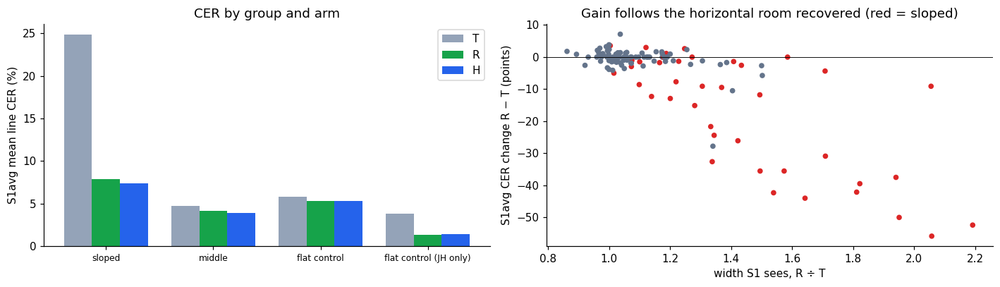

In [22]:
pm = []
for m, s in RS['groups']['sloped'].items():
    pm.append({'reader': m, 'CER T': 100 * s['cer_T'], 'CER R': 100 * s['cer_R'], 'CER H': 100 * s['cer_H'],
               'R-T 95% CI': f"{100*s['R-T']['ci'][0]:+.1f} … {100*s['R-T']['ci'][1]:+.1f}", 'R better/worse': f"{s['R-T']['better']}/{s['R-T']['worse']}",
               'deletions T→R→H': f"{s['D_T']:.0f} → {s['D_R']:.0f} → {s['D_H']:.0f}", 'substitutions T→R→H': f"{s['S_T']:.0f} → {s['S_R']:.0f} → {s['S_H']:.0f}",
               'padding chars T→R→H': f"{s['pad_chars_T']:.0f} → {s['pad_chars_R']:.0f} → {s['pad_chars_H']:.0f}"})
display(Markdown('**Sloped group (n = 40), every reader**')); display(pd.DataFrame(pm).set_index('reader').round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
gs = ['sloped', 'middle', 'flat control', 'flat control (JH only)']
x_ = np.arange(len(gs)); w = .26
for j, (arm, col) in enumerate((('T', '#94a3b8'), ('R', '#16a34a'), ('H', '#2563eb'))):
    ax[0].bar(x_ + (j - 1) * w, [100 * RS['groups'][g]['S1avg'][f'cer_{arm}'] for g in gs], w, label=arm, color=col)
ax[0].set_xticks(x_, gs, fontsize=8); ax[0].set_ylabel('S1avg mean line CER (%)'); ax[0].legend(); ax[0].set_title('CER by group and arm')
cr = [x for x in RS['crops'] if x['processed']]
ax[1].scatter([x['width64']['R'] / x['width64']['T'] for x in cr], [100 * (x['m']['S1avg']['R']['cer'] - x['m']['S1avg']['T']['cer']) for x in cr],
              c=['#dc2626' if x['stratum'] == 'sloped' else '#64748b' for x in cr], s=16)
ax[1].axhline(0, c='k', lw=.6); ax[1].set_xlabel('width S1 sees, R ÷ T'); ax[1].set_ylabel('S1avg CER change R − T (points)')
ax[1].set_title('Gain follows the horizontal room recovered (red = sloped)')
plt.tight_layout(); plt.show()

### 9a · Side by side: the 40 sloped lines

Each panel shows, from left to right:
- **T** (tightened), **R** (straightened) and **H** (stretched);
- under each one: S1avg CER, deletions and characters predicted over the padding, then S1's (seed 1) reading, then all six readers' CER.

Labels are coloured against T: green = better, red = worse. Panels are ordered from the largest improvement.

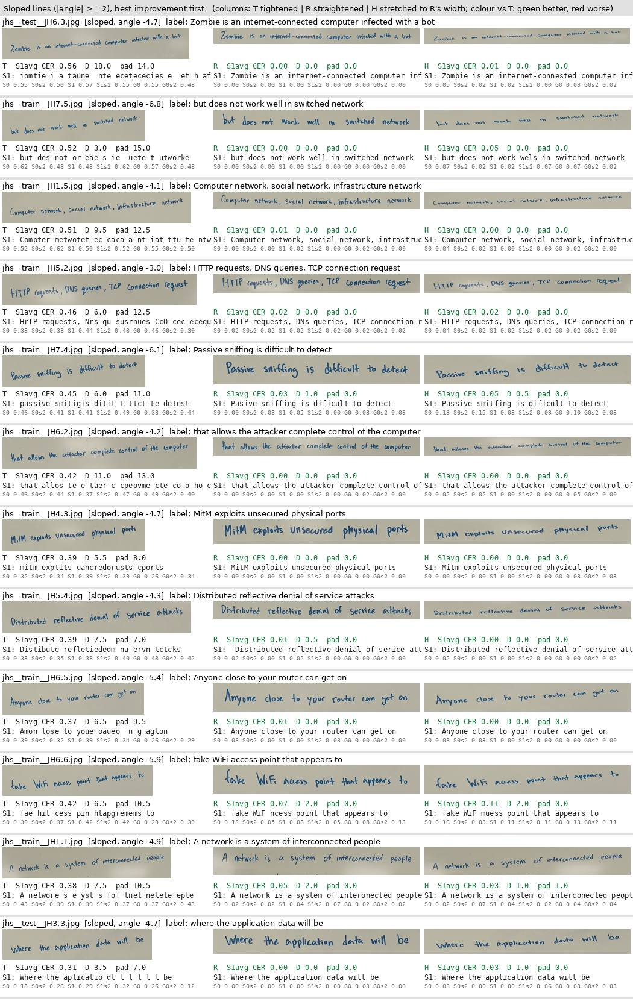

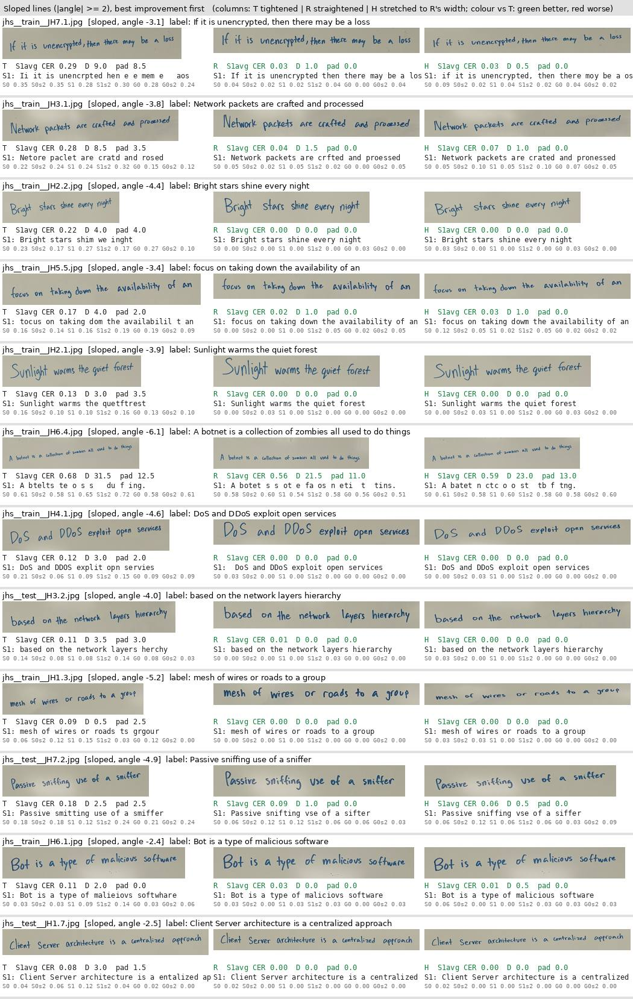

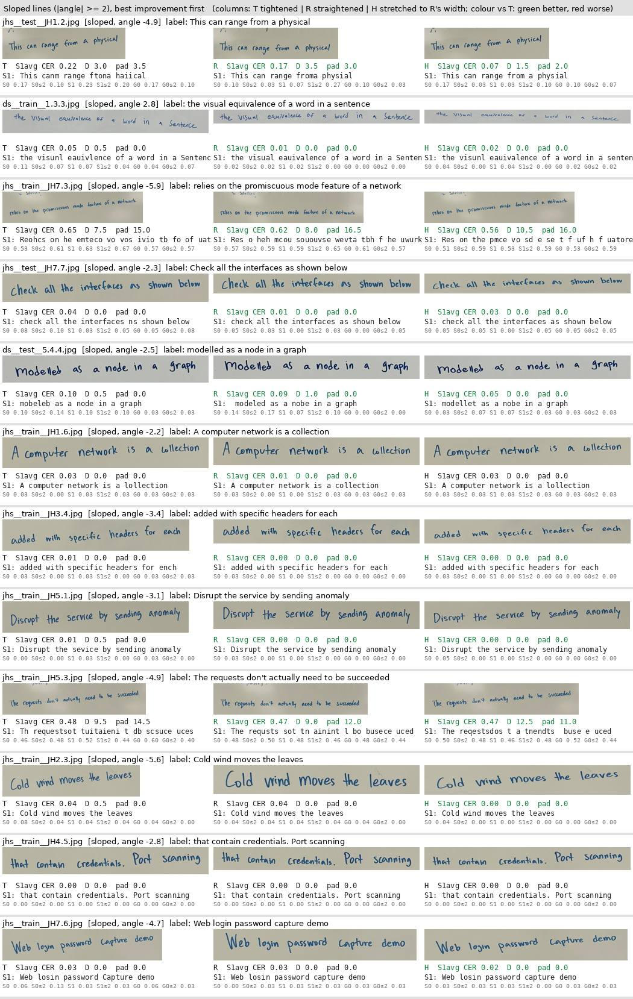

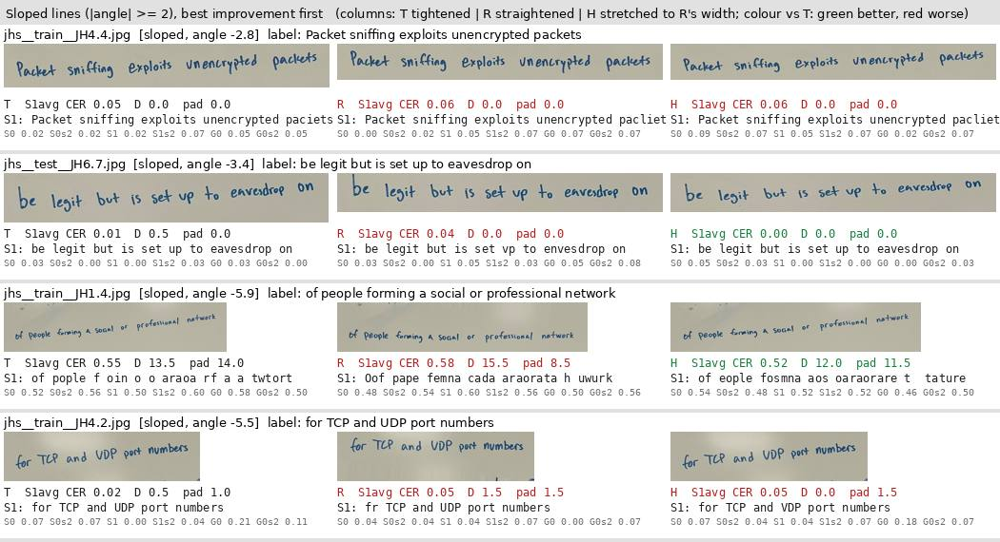

In [23]:
IDX = json.loads((SD / 'sheets/index.json').read_text())
for f in IDX['sloped']:
    display(IPImage(filename=str(SD / 'sheets' / f), width=1050))

### 9b · Regressions

This lists **every** processed crop where S1avg is worse in R than in T, from every group, largest first. The table includes S1's readings in both arms, so the size of each change is visible.

31 regressions (of 125 processed): {'flat control': 21, 'middle': 6, 'sloped': 4} | largest +7.1 points | sum of increases 60.3 points


,crop,group,angle,S1avg CER T,S1avg CER R,change (points),S1 reading T,S1 reading R,label
0,ds__train__6.1.1.jpg,middle,-1.4,0.043,0.114,7.143,Ranu Predictions Sort all prebicted,Ranu Prebictions Sort al prebicted,Rank predictions sort all predicted
1,ds__train__7.3.1.jpg,middle,-1.2,0.103,0.141,3.846,An Optmizationaigorithm to ajst te,An optimization agorithm to djus thte,An Optimization algorithm to adjust the
2,jhs__train__JH4.2.jpg,sloped,-5.5,0.018,0.054,3.571,for TCP and UDP port numbers,fr TCP and UDP port numbers,for TCP and UDP port numbers
3,ds__train__1.1.1.jpg,flat control,0.5,0.359,0.391,3.261,The Vi arcitecture vde e e h e c ec ctes.,The Vi architetuer r e e t et f ece ctes.,The ViT architecture relies on three concepts.
4,jhs__train__JH1.4.jpg,sloped,-5.9,0.550,0.580,3.000,of pople f oin o o araoa rf a a twtort,Oof pape femna cada araorata h uwurk,of people forming a social or professional net...
5,ds__train__2.3.1.jpg,flat control,-0.5,0.056,0.083,2.778,Grid of pretictors method would tail,Gril of pretictors method would tail,Grid of predictors method would fail
6,jhs__test__JH6.7.jpg,sloped,-3.4,0.013,0.039,2.632,be legit but is set up to eavesdrop on,be legit but is set vp to envesdrop on,be legit but is set up to eavesdrop on
7,ds__test__4.1.3.jpg,flat control,0.3,0.073,0.098,2.439,it pooied to see wheve the evidence. lies.,it pooied to see wheve the evitence. lies.,it pooled to see where the evidence lies.
8,jhs__train__JH3.7.jpg,flat control,-0.3,0.000,0.023,2.326,The vulnerability will NEVER cause any risk,The vlnerability will NEVER Cause any risk,The vulnerability will NEVER cause any risk
9,ds__test__6.4.2.jpg,middle,1.2,0.035,0.058,2.326,Ap Scores across all object clases in your,Ap scores across all object Uasces in your,Ap scores across all object classes in your


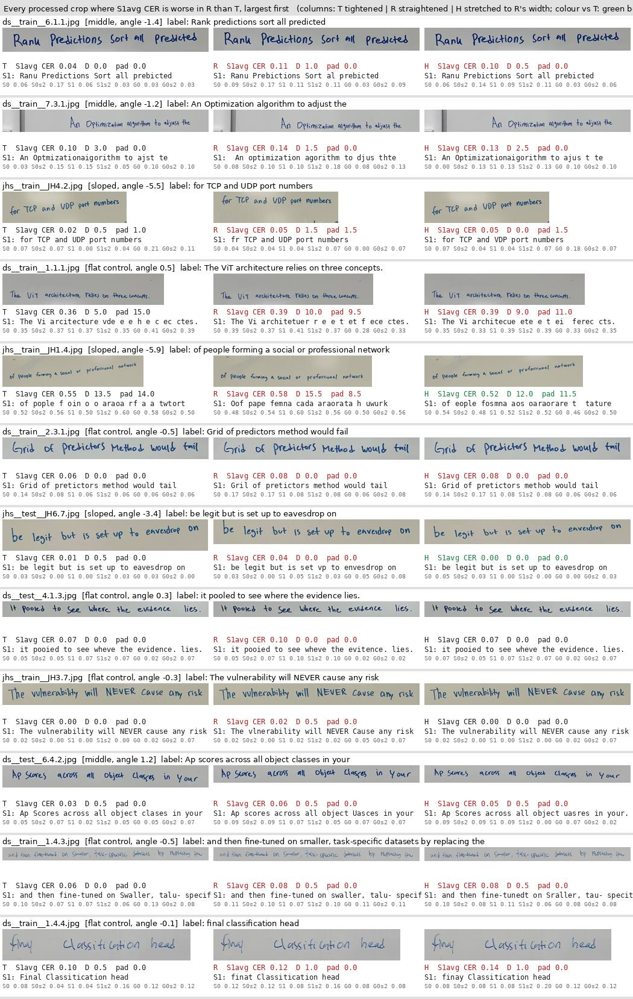

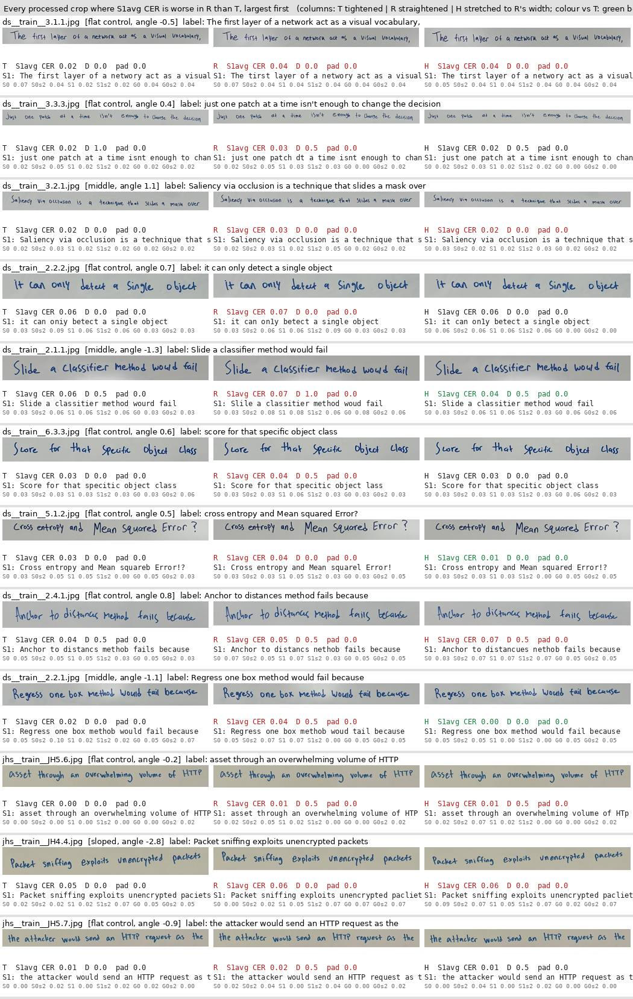

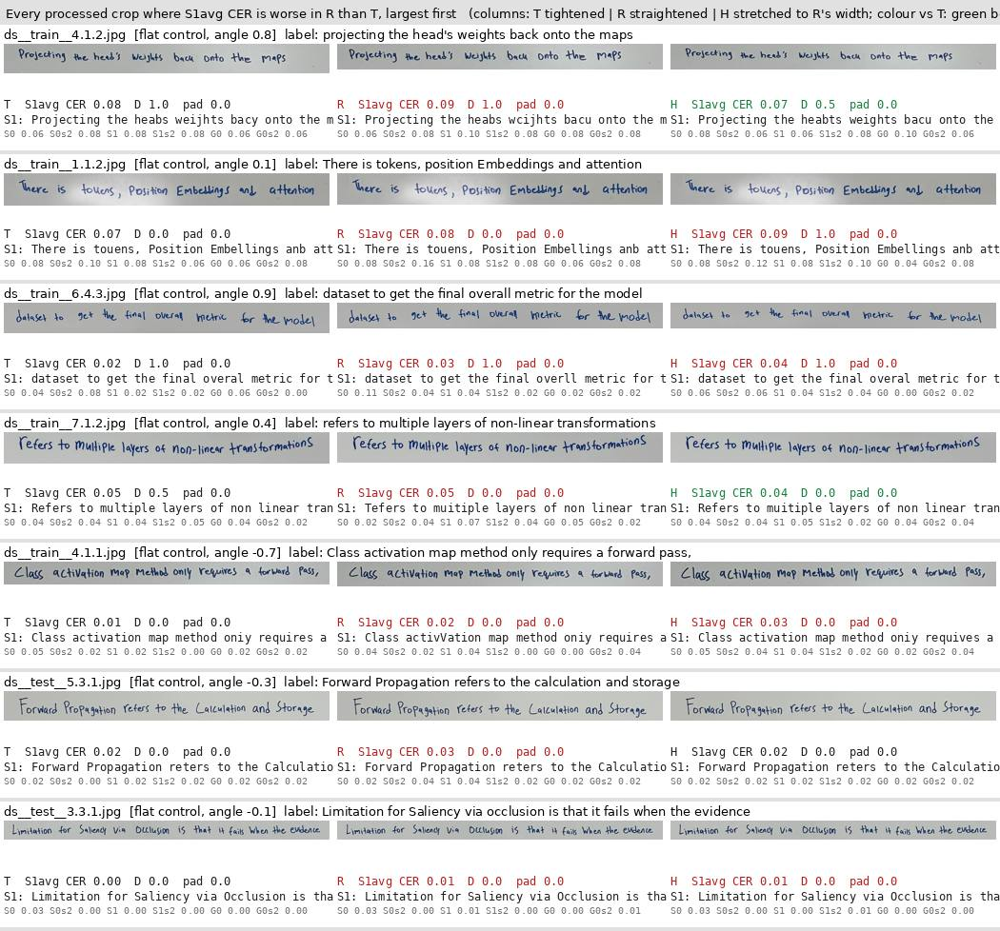

In [24]:
reg = [x for x in RS['crops'] if x['processed'] and x['m']['S1avg']['R']['cer'] > x['m']['S1avg']['T']['cer'] + 1e-12]
reg.sort(key=lambda x: x['m']['S1avg']['T']['cer'] - x['m']['S1avg']['R']['cer'])
RG = pd.DataFrame([{'crop': x['name'], 'group': x['stratum'], 'angle': x['angle'], 'S1avg CER T': x['m']['S1avg']['T']['cer'],
                    'S1avg CER R': x['m']['S1avg']['R']['cer'], 'change (points)': 100 * (x['m']['S1avg']['R']['cer'] - x['m']['S1avg']['T']['cer']),
                    'S1 reading T': x['m']['S1']['T']['pred'], 'S1 reading R': x['m']['S1']['R']['pred'], 'label': x['label']} for x in reg])
print(f"{len(reg)} regressions (of 125 processed):", RG.group.value_counts().to_dict(),
      f"| largest +{RG['change (points)'].max():.1f} points | sum of increases {RG['change (points)'].sum():.1f} points")
display(RG.round(3))
for f in IDX['regressions']:
    display(IPImage(filename=str(SD / 'sheets' / f), width=1050))

### 9c · The 26 previously persistent crops

Words were not processed, so they are identical in every arm.

,crop,group,width at 64 px T→R,S1avg T,S1avg R,S1avg H,still >=15% for all six (R)
3,jhs__train__JH4.3.jpg,sloped,292 → 532,0.395,0.000,0.000,False
7,jhs__train__JH6.2.jpg,sloped,398 → 721,0.421,0.000,0.000,False
14,jhs__train__JH7.5.jpg,sloped,292 → 640,0.524,0.000,0.048,False
15,jhs__test__JH6.3.jpg,sloped,382 → 786,0.558,0.000,0.008,False
2,jhs__train__JH1.5.jpg,sloped,387 → 755,0.509,0.009,0.000,False
6,jhs__train__JH5.4.jpg,sloped,386 → 749,0.385,0.010,0.000,False
9,jhs__train__JH6.5.jpg,sloped,291 → 458,0.368,0.013,0.000,False
4,jhs__train__JH5.2.jpg,sloped,397 → 652,0.460,0.020,0.020,False
13,jhs__train__JH7.4.jpg,sloped,293 → 451,0.449,0.026,0.051,False
11,jhs__train__JH7.1.jpg,sloped,367 → 522,0.293,0.033,0.033,False


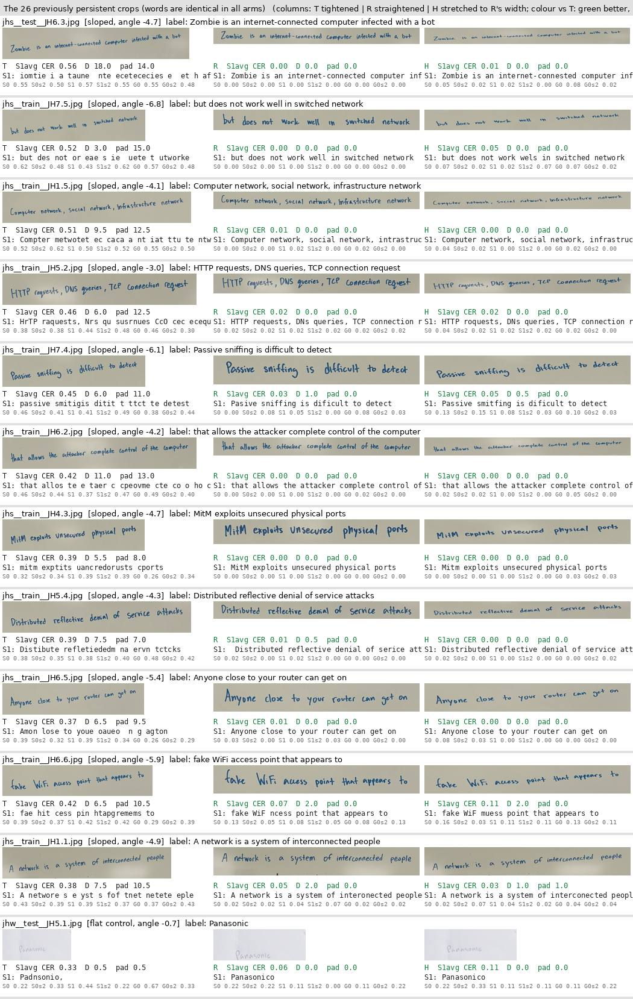

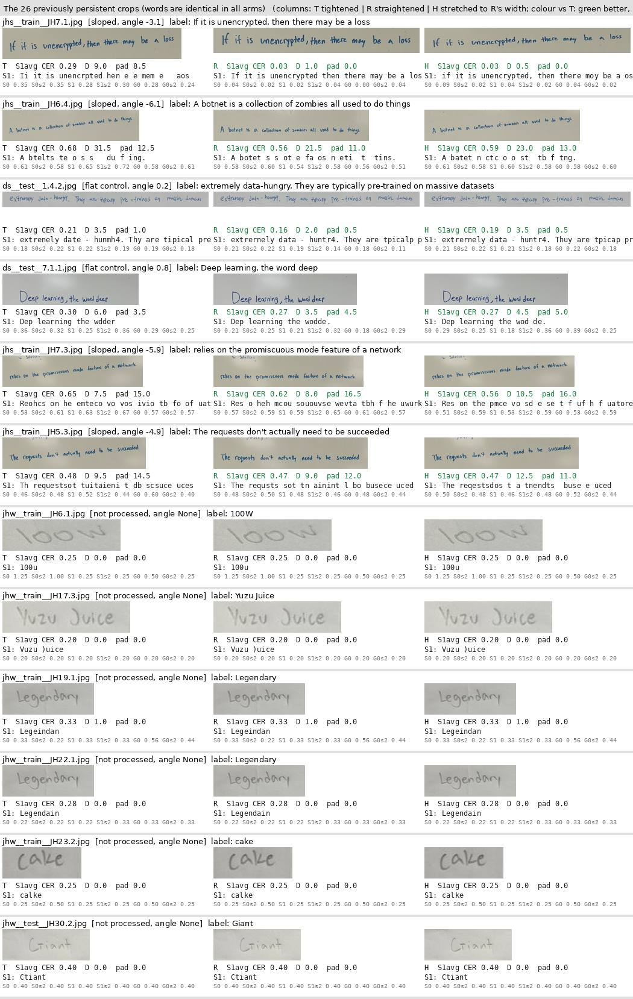

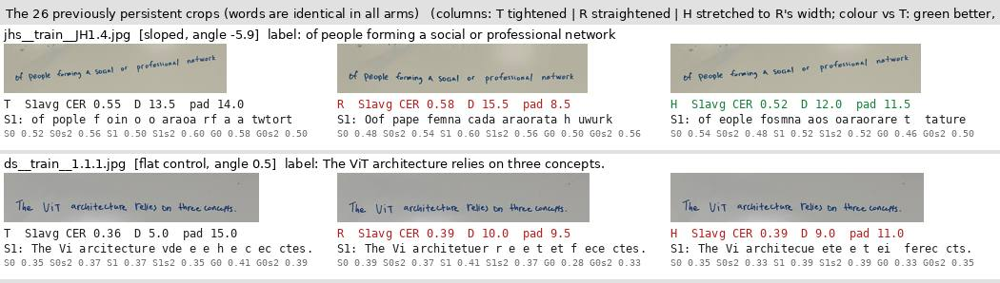

In [25]:
pers_names = set(json.loads((D / 'RESULTS_MODELS.json').read_text())['persistent_tight'])
P26 = pd.DataFrame([{'crop': x['name'], 'group': x['stratum'], 'width at 64 px T→R': (f"{x['width64']['T']} → {x['width64']['R']}" if x['width64'] else 'unchanged'),
                     'S1avg T': x['m']['S1avg']['T']['cer'], 'S1avg R': x['m']['S1avg']['R']['cer'], 'S1avg H': x['m']['S1avg']['H']['cer'],
                     'still >=15% for all six (R)': all(x['m'][m]['R']['cer'] >= .15 for m in MODS)} for x in RS['crops'] if x['name'] in pers_names])
display(P26.round(3).sort_values(['still >=15% for all six (R)', 'S1avg R']))
for f in IDX['persistent26']:
    display(IPImage(filename=str(SD / 'sheets' / f), width=1050))

### 9d · What the experiment shows

**Primary rule: supported.** On the 40 sloped lines, S1avg falls from **24.9 % to 7.9 %**: −16.9 points, 95 % CI −20.8 to −12.2.
- 33 crops get better and 4 get worse.
- Deletions fall from 202 to 70.
- **All six readers** improve, each with a CI below 0.
- Across all 160 crops, S1avg falls from 11.0 % to 6.4 %.

**Safety: met.**
- On the 62 flat controls, the change is −0.5 points (CI −2.0 to +0.1), with 20 better and 21 worse. That is noise-sized, so processing an already-level line does not hurt.
- The 13 JH flat lines improve slightly (3.8 % → 1.3 %), but the CI is wide.

**Mechanism: horizontal resolution.** Stretching without rotating (H) recovers as much as straightening does:
- 7.4 % vs 7.9 %, R − H = +0.5 points (CI −0.3 to +1.4), f ≈ 1.0.
- The slope matters only because it makes the upright box tall. Resizing to 64 px high then leaves the line too short, so the text covers too few of S1's 128 output positions.
- The dose-response agrees. The sloped lines that recovered a lot of width (T ≈ 290–400 px → R ≈ 450–790 px) are almost all fixed. The 4 that are still bad (JH1.4, JH5.3, JH6.4, JH7.3) gained only about 20–40 px. Their boxes stay tall because the all-components rule keeps residue marks and specks above the line.
- The same holds for the two DS lines that keep a blank band (DS 1.1.1 and DS 7.1.1): their width barely changed, and neither improved.

**Padding diagnostic** (secondary, sloped group): crops with text predicted over the padding fall from 28 to 6 (R) and 7 (H). For S1avg, characters there fall from 224 to 53.

**Regressions.** 31 of the 125 processed crops read worse in R (21 flat controls, 6 middle, 4 sloped).
- All are small, mostly one- or two-character changes; the largest is +7.1 points (DS 6.1.1, "Predictions" → "Prebictions").
- The sum of all increases is far smaller than the gains.

**Still persistent:** 12 of the 26.
- 7 unprocessed words (letterform cases).
- The 4 sloped lines kept tall by residue.
- 1 DS line with a blank band kept by a speck.

**What this means and what it doesn't.**
- Much of the remaining JH sentence gap on these crops is a **crop-geometry artifact** (writing too short for the reader after the 64-px resize), not unfamiliar handwriting.
- These are still dataset crops with oracle-style boxes, not the app path. JH and DS are also development data now, and the CPU scorer reproduced every saved tightened reading exactly.
- Possible next steps, none run yet:
  1. Check whether the app's rotated detector crops already avoid this on JH's full photos.
  2. Look for a label-free rule that guarantees enough output positions per character.
  3. Re-score the new-writer benchmark with corrected crops before drawing training conclusions.